# 📋 Задание 3. Метода аналиа LDA, QDA и тд

### [3.1] Создание датасета

Используя функцию `multivariate_normal` (numpy) с любым `random_state`, сгенерировать датасет `df1`, в котором есть три класса с размером каждого класса 100 объектов и 16 количественных (недискретных) признаков. Распределения двух из трех классов должны значительно перекрывать друг друга, тогда как третий класс должен быть на расстоянии от первых двух классов.

In [55]:
import numpy as np
import pandas as pd

np.random.seed(42)  # фиксируем random_state

# Количество объектов и признаков
n = 100
n_features = 16

# Средние значения для трех классов
mean0 = [0] * n_features       # класс 0
mean1 = [0.5] * n_features     # класс 1 (перекрывается с классом 0)
mean2 = [5] * n_features       # класс 2 (удален от первых двух)

# Ковариационная матрица
cov = np.eye(n_features)

# Генерация данных для каждого класса
data0 = np.random.multivariate_normal(mean0, cov, size=n)
data1 = np.random.multivariate_normal(mean1, cov, size=n)
data2 = np.random.multivariate_normal(mean2, cov, size=n)

# Объединение данных
data = np.vstack([data0, data1, data2])

# Создание DataFrame
df1 = pd.DataFrame(data, columns=[f'X{i+1}' for i in range(n_features)])

# Добавление целевого класса
df1['class'] = np.repeat([0, 1, 2], n)

# Вывод первых строк
display(df1.head(5))

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,X11,X12,X13,X14,X15,X16,class
0,0.496714,-0.138264,0.647689,1.523030,-0.234153,-0.234137,1.579213,0.767435,-0.469474,0.542560,-0.463418,-0.465730,0.241962,-1.913280,-1.724918,-0.562288,0
1,-1.012831,0.314247,-0.908024,-1.412304,1.465649,-0.225776,0.067528,-1.424748,-0.544383,0.110923,-1.150994,0.375698,-0.600639,-0.291694,-0.601707,1.852278,0
2,-0.013497,-1.057711,0.822545,-1.220844,0.208864,-1.959670,-1.328186,0.196861,0.738467,0.171368,-0.115648,-0.301104,-1.478522,-0.719844,-0.460639,1.057122,0
3,0.343618,-1.763040,0.324084,-0.385082,-0.676922,0.611676,1.031000,0.931280,-0.839218,-0.309212,0.331263,0.975545,-0.479174,-0.185659,-1.106335,-1.196207,0
4,0.812526,1.356240,-0.072010,1.003533,0.361636,-0.645120,0.361396,1.538037,-0.035826,1.564644,-2.619745,0.821903,0.087047,-0.299007,0.091761,-1.987569,0


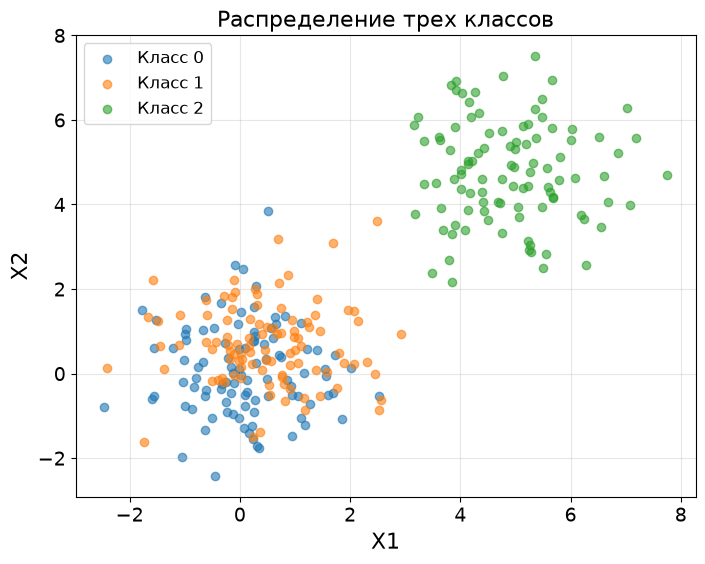

In [56]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for cls in [0, 1, 2]:
    subset = df1[df1['class'] == cls]

    plt.scatter(
        subset['X1'],
        subset['X2'],
        label=f'Класс {cls}',
        alpha=0.6
    )

plt.xlabel('X1')
plt.ylabel('X2')
plt.title('Распределение трех классов')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### Базовый анализ
- ключевые характеристики датасета
- корреляции
- визуализация панно scatterplot на всех парах переменных

In [57]:
# Размерность всего датасета (объекты и признаки) 
print(f'Размерность датасета: {df1.shape}\n')

# Тип каждого признака
print(f'Тип каждого признака: \n{df1.dtypes}\n')

# Количество классов и объектов в каждом из классов
counts = df1['class'].value_counts().sort_index()
print('Объектов в каждом классе:')
print(f'{counts}\n')

Размерность датасета: (300, 17)

Тип каждого признака: 
X1       float64
X2       float64
X3       float64
X4       float64
X5       float64
X6       float64
X7       float64
X8       float64
X9       float64
X10      float64
X11      float64
X12      float64
X13      float64
X14      float64
X15      float64
X16      float64
class      int64
dtype: object

Объектов в каждом классе:
class
0    100
1    100
2    100
Name: count, dtype: int64



In [58]:
# Иные оценки выборки
def describe_extended(series):
    x = series.values
    
    q1, q3 = np.percentile(x, [25, 75])
    iqr = q3 - q1

    return pd.Series({
        'mean': np.mean(x),
        'median': np.median(x),
        'std': np.std(x, ddof=1),
        'var': np.var(x, ddof=1),
        'min': np.min(x),
        'max': np.max(x),
        'q1': q1,
        'q3': q3,
        'iqr': iqr,
    })
stats_table = df1.drop(columns=['class']).apply(describe_extended)
print('Различные оценки выборки: ')
print(stats_table.T.round(3), '\n')

Различные оценки выборки: 
      mean  median    std    var    min    max     q1     q3    iqr
X1   1.823   0.914  2.393  5.726 -2.472  7.755 -0.016  4.045  4.061
X2   1.843   1.067  2.350  5.521 -2.424  7.512  0.014  3.941  3.927
X3   1.756   0.892  2.374  5.637 -2.554  7.050 -0.065  4.268  4.332
X4   1.809   0.942  2.401  5.767 -2.872  6.629 -0.050  4.268  4.318
X5   1.931   0.861  2.564  6.575 -2.248  8.243 -0.021  4.726  4.747
X6   1.810   0.991  2.443  5.970 -2.849  7.308 -0.218  4.213  4.431
X7   1.820   1.061  2.461  6.054 -3.241  7.485 -0.027  4.403  4.430
X8   1.876   0.945  2.490  6.200 -2.921  7.320 -0.085  4.482  4.566
X9   1.823   0.871  2.566  6.582 -2.520  7.304 -0.176  4.512  4.688
X10  1.854   0.968  2.373  5.629 -2.332  7.868  0.040  4.306  4.266
X11  1.807   1.009  2.430  5.906 -2.620  7.349 -0.076  4.193  4.270
X12  1.861   0.988  2.435  5.930 -2.591  7.213 -0.060  4.125  4.185
X13  1.850   0.980  2.403  5.773 -2.651  7.388  0.050  4.208  4.158
X14  1.848   0.978  2

In [59]:
# Число объектов с NaN по классам
print('Число объектов с NaN по классам: ')
print(df1.groupby('class').apply(lambda g: g.isna().any(axis=1).sum()))


# Число объектов с 0 по классам
print('\nЧисло объектов с 0 по классам: ')
features = [c for c in df1.columns if c != 'class']
print(df1.groupby('class')[features].apply(lambda g: (g == 0).any(axis=1).sum()))


Число объектов с NaN по классам: 
class
0    0
1    0
2    0
dtype: int64

Число объектов с 0 по классам: 
class
0    0
1    0
2    0
dtype: int64


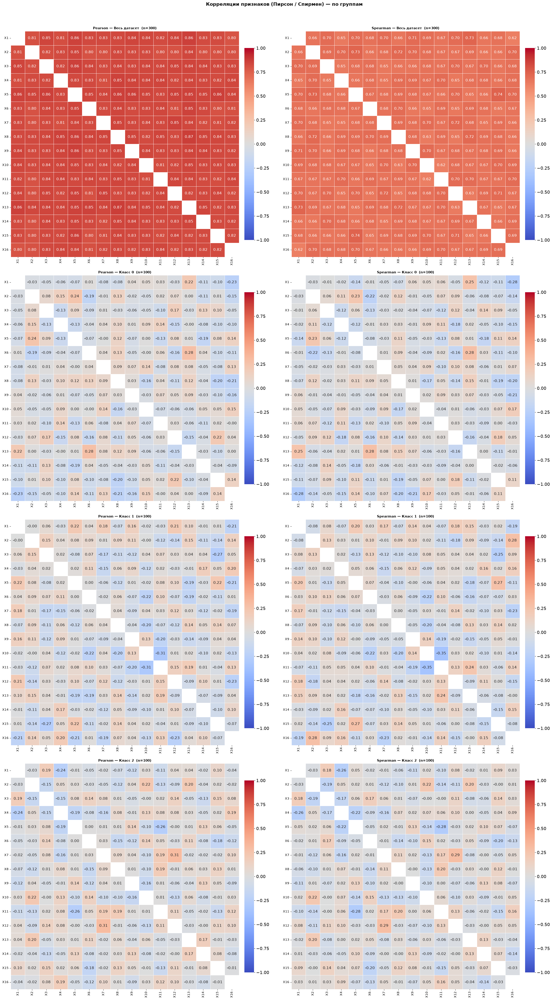

In [60]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


def plot_correlation_heatmaps(
    df, features, class_col='class',
    cell_in=0.62,        # дюймов на одну ячейку -> чем больше признаков, тем шире фигура
    annot_fs=12,        # шрифт чисел в ячейке
    tick_fs=10,           # шрифт подписей X1..X16
    fmt='.2f',           # '.1f' даст ещё свободнее, если вдруг всё равно тесно
    mask_diag=True,      # спрятать диагональ (=1.00), чтобы не мешала глазу
    cmap='coolwarm',
):
    """
    Тепловые карты Пирсона и Спирмена: весь датасет + каждый класс.
    Размер фигуры подбирается ПОД ЧИСЛО ПРИЗНАКОВ, поэтому 16x16 остаётся читаемым.
    """
    groups = [('Весь датасет', df)] + [
        (f'Класс {c}', d) for c, d in df.groupby(class_col)
    ]
    n_g   = len(groups)
    n_f   = len(features)

    hm_w  = n_f * cell_in + 2.4          # ширина одной heatmap (с подписями и colorbar)
    hm_h  = n_f * cell_in + 1.0          # высота строки (квадратные ячейки + заголовок)
    fig_w = 2 * hm_w + 1.0
    fig_h = n_g * hm_h + 1.0

    diag  = np.eye(n_f, dtype=bool) if mask_diag else None

    fig, axes = plt.subplots(n_g, 2, figsize=(fig_w, fig_h), squeeze=False)

    for i, (name, data) in enumerate(groups):
        for j, method in enumerate(['pearson', 'spearman']):
            corr = data[features].corr(method=method)
            ax   = axes[i, j]

            sns.heatmap(
                corr, mask=diag, annot=True, fmt=fmt,
                cmap=cmap, vmin=-1, vmax=1, center=0,
                linewidths=0.4, linecolor='white',
                cbar_kws={'shrink': 0.85, 'pad': 0.02},
                annot_kws={'fontsize': annot_fs},
                xticklabels=features, yticklabels=features,
                ax=ax,
            )

            # подписи осей: X вертикально, Y горизонтально, мелким но чётким шрифтом
            ax.set_xticklabels(ax.get_xticklabels(), rotation=90,
                               fontsize=tick_fs, ha='center')
            ax.set_yticklabels(ax.get_yticklabels(), rotation=0,
                               fontsize=tick_fs, va='center')
            ax.set_title(f'{method.capitalize()} — {name}  (n={len(data)})',
                         fontsize=11, fontweight='bold')
            ax.set_xlabel(''); ax.set_ylabel('')

    fig.suptitle('Корреляции признаков (Пирсон / Спирмен) — по группам',
                 fontsize=15, fontweight='bold', y=0.999)
    plt.tight_layout(rect=(0, 0, 1, 0.99))
    plt.show()


plot_correlation_heatmaps(df1, features)

In [61]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, AutoLocator, AutoMinorLocator
from matplotlib.lines import Line2D
from scipy import stats
from itertools import combinations
import math
import seaborn as sns

# ============================================================
# ГЛОБАЛЬНЫЕ НАСТРОЙКИ ШРИФТА
# ============================================================
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 16
plt.rcParams['axes.labelsize'] = 16
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 14
plt.rcParams['ytick.labelsize'] = 14
plt.rcParams['legend.fontsize'] = 12


def custom_scatter(
    ax, x, y,                          # объект Axes и массивы координат X, Y
    class_values=None,                 # массив классов точек (0/1) для раскраски
    
    # === Шрифт ===
    font_family="DejaVu Sans",         # семейство шрифта для всех текстовых элементов
    font_size=16,                      # базовый размер шрифта
    
    # === Точки ===
    point_size=30,                     # размер маркеров точек
    point_alpha=0.55,                  # прозрачность точек (0..1)
    point_colors=None,                 # цвета для классов (None = авто)
    point_edgecolor="none",            # цвет обводки точек
    point_linewidth=0.5,               # толщина обводки точек
    point_marker="o",                  # форма маркера ("o" - круг, "s" - квадрат)
    
    # === Рамка ===
    spine_color="black",               # цвет рамок осей
    spine_width=1.5,                   # толщина рамок осей
    show_top_spine=True,               # показывать верхнюю рамку
    show_right_spine=True,             # показывать правую рамку
    
    # === Деления ===
    major_step="auto",                 # шаг основных делений (число или "auto")
    minor_step="auto",                 # шаг промежуточных делений (число или "auto")
    n_minor_ticks=4,                   # количество промежуточных делений между основными
    tick_length=6,                     # длина основных делений
    minor_tick_length=3,               # длина промежуточных делений
    tick_width=1.5,                    # толщина основных делений
    minor_tick_width=1,                # толщина промежуточных делений
    tick_direction="out",              # направление делений ("out", "in", "inout")
    tick_label_size=None,              # размер цифр на осях (None = font_size - 2)
    tick_label_color="black",          # цвет цифр на осях
    
    # === Сетка ===
    show_grid=True,                    # показывать сетку
    grid_which="major",                # по каким делениям рисовать сетку ("major", "minor", "both")
    grid_color="gray",                 # цвет сетки
    grid_alpha=0.25,                   # прозрачность сетки
    grid_linestyle="--",               # стиль линии сетки ("-", "--", ":", "-.")
    grid_linewidth=0.5,                # толщина линий сетки
    
    # === Подписи ===
    xlabel=None,                       # подпись оси X
    ylabel=None,                       # подпись оси Y
    label_size=None,                   # размер подписей осей (None = font_size)
    label_weight="normal",             # начертание подписей ("normal", "bold")
    
    # === Заголовок ===
    title=None,                        # заголовок графика
    title_size=None,                   # размер заголовка (None = font_size)
    title_weight="bold",               # начертание заголовка
    
    # === Регрессия ===
    show_correlation=True,             # показывать линию регрессии
    correlation_color="darkred",       # цвет линии регрессии
    correlation_width=2,               # толщина линии регрессии
    
    # === Доверительный интервал линии регрессии ===
    show_confidence_band=True,         # показывать доверительный интервал для линии регрессии
    confidence_band_color="orange",    # цвет доверительного интервала
    confidence_band_alpha=0.2,         # прозрачность доверительного интервала
    confidence_band_linestyle="-",     # стиль линии границ доверительного интервала
    confidence_band_linewidth=1,       # толщина линии границ доверительного интервала
    confidence_band_level=0.95,        # уровень доверия (0.95 = 95%)
    
    # === Интервал предсказания ===
    show_prediction_interval=True,     # показывать интервал предсказания для новых точек
    confidence_level=0.95,             # уровень доверия интервала предсказания
    interval_color="lightblue",        # цвет интервала предсказания
    interval_alpha=0.3,                # прозрачность интервала предсказания
    interval_linestyle="--",           # стиль линии границ интервала предсказания
    interval_linewidth=1,              # толщина линии границ интервала предсказания
    
    # === Интервалы значений ===
    show_intervals=True,               # показывать информацию об интервалах ΔX
    interval_position="top",           # положение текста интервалов ("top", "bottom")
    
    # === Легенда ===
    show_legend=True,                  # показывать легенду
    legend_loc="upper right",          # расположение легенды
    legend_fontsize=None,              # размер шрифта легенды (None = font_size - 4)
    legend_framealpha=0.9,             # прозрачность фона легенды
    
    # === Масштаб ===
    x_lim=None,                        # пределы оси X (min, max) или None для авто
    y_lim=None,                        # пределы оси Y (min, max) или None для авто
    equal_scale=False,                 # одинаковый физический масштаб осей X и Y
):
    """
    Построение scatter plot с регрессией, доверительным интервалом 
    и интервалом предсказания.
    """
    x, y = np.asarray(x, dtype=float), np.asarray(y, dtype=float)
    
    # Значения по умолчанию для размеров шрифтов
    if tick_label_size is None:
        tick_label_size = max(font_size - 2, 8)
    if label_size is None:
        label_size = font_size
    if title_size is None:
        title_size = font_size
    if legend_fontsize is None:
        legend_fontsize = max(font_size - 4, 8)
    
    # --- Scatter ---
    if class_values is not None:
        classes = np.unique(class_values[~np.isnan(class_values)])
        
        if point_colors is None:
            colors = plt.cm.tab10(np.linspace(0, 1, max(len(classes), 1)))
        elif isinstance(point_colors, str):
            colors = [point_colors] * len(classes)
        else:
            colors = point_colors
        
        for cls, color in zip(classes, colors):
            mask = class_values == cls
            ax.scatter(
                x[mask], y[mask],
                s=point_size,
                alpha=point_alpha,
                color=color,
                marker=point_marker,
                edgecolors=point_edgecolor,
                linewidths=point_linewidth,
                label=f"Класс {int(cls)}",
                zorder=3
            )
    else:
        color = point_colors if isinstance(point_colors, str) else "steelblue"
        ax.scatter(
            x, y,
            s=point_size,
            alpha=point_alpha,
            color=color,
            marker=point_marker,
            edgecolors=point_edgecolor,
            linewidths=point_linewidth,
            zorder=3
        )
    
    # --- Корреляция и интервалы ---
    r = None
    dx_mean = None
    dx_median = None
    a = None
    b = None
    x_line = None
    y_line = None
    n = None
    x_mean = None
    residual_std = None
    ss_x = None
    
    if show_correlation and len(x) > 1:
        r = np.corrcoef(x, y)[0, 1]
        a, b = np.polyfit(x, y, 1)
        
        x_line = np.linspace(x.min(), x.max(), 300)
        y_line = a * x_line + b
        
        n = len(x)
        x_mean = np.mean(x)
        y_pred = a * x + b
        residuals = y - y_pred
        residual_std = np.sqrt(np.sum(residuals**2) / (n - 2))
        ss_x = np.sum((x - x_mean)**2)
        
        # Линия регрессии
        ax.plot(
            x_line, y_line,
            color=correlation_color,
            lw=correlation_width,
            zorder=4,
            label=f"r = {r:.3f}"
        )
        
        # Доверительный интервал линии регрессии (confidence band)
        if show_confidence_band and ss_x > 0:
            t_crit_ci = stats.t.ppf((1 + confidence_band_level) / 2, df=n-2)
            se_fit = residual_std * np.sqrt(1/n + (x_line - x_mean)**2 / ss_x)
            
            y_ci_upper = y_line + t_crit_ci * se_fit
            y_ci_lower = y_line - t_crit_ci * se_fit
            
            # Заливка доверительного интервала
            ax.fill_between(
                x_line, y_ci_lower, y_ci_upper,
                color=confidence_band_color,
                alpha=confidence_band_alpha,
                zorder=2,
                label=f"{confidence_band_level*100:.0f}% CI (линия)"
            )
            
            # Линии границ доверительного интервала
            ax.plot(
                x_line, y_ci_upper,
                color=confidence_band_color,
                linestyle=confidence_band_linestyle,
                linewidth=confidence_band_linewidth,
                alpha=min(confidence_band_alpha + 0.3, 1.0),
                zorder=3
            )
            ax.plot(
                x_line, y_ci_lower,
                color=confidence_band_color,
                linestyle=confidence_band_linestyle,
                linewidth=confidence_band_linewidth,
                alpha=min(confidence_band_alpha + 0.3, 1.0),
                zorder=3
            )
        
        # Интервал предсказания (prediction interval)
        if show_prediction_interval and ss_x > 0:
            t_crit_pi = stats.t.ppf((1 + confidence_level) / 2, df=n-2)
            se_pred = residual_std * np.sqrt(1 + 1/n + (x_line - x_mean)**2 / ss_x)
            
            y_pi_upper = y_line + t_crit_pi * se_pred
            y_pi_lower = y_line - t_crit_pi * se_pred
            
            ax.fill_between(
                x_line, y_pi_lower, y_pi_upper,
                color=interval_color,
                alpha=interval_alpha,
                zorder=2,
                label=f"{confidence_level*100:.0f}% PI (прогноз)"
            )
            
            ax.plot(
                x_line, y_pi_upper,
                color=interval_color,
                linestyle=interval_linestyle,
                linewidth=interval_linewidth,
                alpha=min(interval_alpha + 0.3, 1.0),
                zorder=3
            )
            ax.plot(
                x_line, y_pi_lower,
                color=interval_color,
                linestyle=interval_linestyle,
                linewidth=interval_linewidth,
                alpha=min(interval_alpha + 0.3, 1.0),
                zorder=3
            )
    
    # --- Delta X ---
    if show_intervals and len(x) > 1:
        dx = np.diff(np.sort(x))
        dx_mean = dx.mean()
        dx_median = np.median(dx)
    
    # --- Легенда ---
    if show_legend:
        legend_elements = []
        
        if class_values is not None:
            classes = np.unique(class_values[~np.isnan(class_values)])
            if point_colors is None:
                colors = plt.cm.tab10(np.linspace(0, 1, max(len(classes), 1)))
            elif isinstance(point_colors, str):
                colors = [point_colors] * len(classes)
            else:
                colors = point_colors
            
            for cls, color in zip(classes, colors):
                legend_elements.append(
                    Line2D([0], [0], marker=point_marker, color='w',
                           markerfacecolor=color, markersize=8,
                           label=f"Класс {int(cls)}")
                )
        
        if r is not None:
            legend_elements.append(
                Line2D([0], [0], marker='', color='w',
                       label=f"r = {r:.3f}")
            )
        
        if show_confidence_band:
            legend_elements.append(
                Line2D([0], [0], marker='', color=confidence_band_color,
                       linestyle='-', linewidth=2, alpha=0.7,
                       label=f"{confidence_band_level*100:.0f}% CI (линия регрессии)")
            )
        
        if show_prediction_interval:
            legend_elements.append(
                Line2D([0], [0], marker='', color=interval_color,
                       linestyle='--', linewidth=2, alpha=0.7,
                       label=f"{confidence_level*100:.0f}% PI (прогноз)")
            )
        
        if legend_elements:
            ax.legend(
                handles=legend_elements,
                loc=legend_loc,
                fontsize=legend_fontsize,
                framealpha=legend_framealpha,
                edgecolor='gray'
            )
    
    # --- Пределы ---
    if x_lim is not None:
        ax.set_xlim(x_lim)
    if y_lim is not None:
        ax.set_ylim(y_lim)
    
    # --- Spines ---
    for name, spine in ax.spines.items():
        spine.set_color(spine_color)
        spine.set_linewidth(spine_width)
    
    ax.spines["top"].set_visible(show_top_spine)
    ax.spines["right"].set_visible(show_right_spine)
    
    # --- Деления ---
    if major_step == "auto":
        ax.xaxis.set_major_locator(AutoLocator())
        ax.yaxis.set_major_locator(AutoLocator())
    else:
        ax.xaxis.set_major_locator(MultipleLocator(major_step))
        ax.yaxis.set_major_locator(MultipleLocator(major_step))
    
    if minor_step == "auto":
        ax.xaxis.set_minor_locator(AutoMinorLocator(n_minor_ticks))
        ax.yaxis.set_minor_locator(AutoMinorLocator(n_minor_ticks))
    else:
        ax.xaxis.set_minor_locator(MultipleLocator(minor_step))
        ax.yaxis.set_minor_locator(MultipleLocator(minor_step))
    
    ax.tick_params(
        which="major",
        direction=tick_direction,
        length=tick_length,
        width=tick_width,
        labelsize=tick_label_size,
        labelcolor=tick_label_color
    )
    ax.tick_params(
        which="minor",
        direction=tick_direction,
        length=minor_tick_length,
        width=minor_tick_width
    )
    
    # --- Grid ---
    if show_grid:
        ax.grid(
            which=grid_which,
            color=grid_color,
            alpha=grid_alpha,
            linestyle=grid_linestyle,
            linewidth=grid_linewidth
        )
    
    # --- Labels ---
    if xlabel is not None:
        ax.set_xlabel(xlabel, fontsize=label_size, fontweight=label_weight, fontfamily=font_family)
    if ylabel is not None:
        ax.set_ylabel(ylabel, fontsize=label_size, fontweight=label_weight, fontfamily=font_family)
    if title is not None:
        ax.set_title(title, fontsize=title_size, fontweight=title_weight, fontfamily=font_family)
    
    if equal_scale:
        ax.set_aspect("equal", adjustable="box")
    
    return ax


def make_kde(
    ax,
    df,
    feature,
    class_col="class",
    font_family="DejaVu Sans",
    font_size=16,
    kde_alpha=0.25,
    kde_linewidth=2,
    show_legend=True,
    show_grid=True,
):
    """KDE распределения одного признака отдельно по классам."""

    if class_col not in df.columns:
        raise ValueError(f"Колонка класса '{class_col}' не найдена в DataFrame.")

    classes = sorted(df[class_col].dropna().unique())

    # Общий диапазон признака, чтобы все KDE на диагонали имели
    # одинаковую x-шкалу для данного признака.
    feature_values = df[feature].dropna()
    if len(feature_values) == 0:
        ax.set_title(f"KDE: {feature}", fontsize=font_size, fontweight="bold")
        return ax

    for cls in classes:
        values = df.loc[df[class_col] == cls, feature].dropna().astype(float)

        # KDE требует минимум двух наблюдений и ненулевую дисперсию.
        if len(values) < 2:
            continue

        if np.isclose(values.std(ddof=1), 0):
            # Для константного распределения рисуем вертикальную линию,
            # чтобы KDE не падал.
            ax.axvline(
                values.iloc[0],
                linewidth=kde_linewidth,
                label=f"Класс {int(cls)}"
            )
            continue

        sns.kdeplot(
            x=values,
            ax=ax,
            fill=True,
            alpha=kde_alpha,
            linewidth=kde_linewidth,
            label=f"Класс {int(cls)}",
        )

    ax.set_title(
        f"KDE: {feature}",
        fontsize=font_size,
        fontweight="bold",
        fontfamily=font_family,
    )
    ax.set_xlabel(feature, fontsize=font_size, fontfamily=font_family)
    ax.set_ylabel("Плотность", fontsize=font_size, fontfamily=font_family)

    if show_grid:
        ax.grid(True, alpha=0.2, linestyle="--")

    if show_legend and ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=max(font_size - 4, 8))

    return ax

In [62]:
def plot_feature_combinations_panel(
    df,
    feature,                      # <-- ОПОРНЫЙ признак, панно рисуется только для него
    features=None,
    class_col="class",
    *,
    # --- компоновка панно ---
    cols=None,                    # колонок в сетке; None = ceil(sqrt(n_features)) -> 16 => 4x4
    subplot_size=3.2,
    margin=2.4,
    scale_mode="per_feature",     # 'per_feature' | 'global' | 'individual'
    pad=0.04,
    # --- шрифты (явно в custom_scatter) ---
    font_size=11, tick_label_size=9, label_size=10, title_size=10,
    font_family="DejaVu Sans",
    # --- точки ---
    point_size=8, point_alpha=0.5, point_edgecolor="none",
    point_linewidth=0.0, point_marker="o", point_colors=None,
    # --- регрессия / полосы ---
    show_correlation=True, correlation_color="darkred", correlation_width=1.2,
    show_confidence_band=False, show_prediction_interval=False,
    confidence_band_color="orange", interval_color="lightblue",
    confidence_band_level=0.95, confidence_level=0.95,
    # --- KDE в нулевой ячейке ---
    kde_alpha=0.30, kde_linewidth=1.2,
    # --- прочее ---
    show_grid=False,
    # --- вывод ---
    suptitle_fmt="Признак {feat}: KDE + комбинации с остальными признаками",
    suptitle_size=15,
    save_path=None,               # один файл на одно панно (вместо save_prefix)
    file_dpi=200,
    show_in_notebook=True,
):
    """
    Одно панно: [KDE(feature)] + [scatter feature ~ X_j для всех j != feature].
    Ячеек = len(features) (1 KDE + nf-1 scatter); сетка rows x cols подобрана под них.
    """
    if features is None:
        features = [c for c in df.columns if c != class_col]
    nf = len(features)
    if nf == 0:
        print("Нет признаков."); return None
    if feature not in features:
        raise ValueError(f"feature='{feature}' нет среди признаков. Доступны: {features}")

    if cols is None:
        cols = int(math.ceil(math.sqrt(nf)))
    rows = int(math.ceil(nf / cols))

    cv_series = df[class_col] if class_col in df.columns else None

    # ---- пределы осей ----
    def _lim(series):
        v = series.dropna().astype(float)
        if v.empty:
            return None
        lo, hi = float(v.min()), float(v.max()); d = hi - lo
        if d <= 0:
            d = max(abs(hi), 1.0)
        return (lo - d * pad, hi + d * pad)

    if scale_mode == "global":
        g = _lim(pd.concat([df[f] for f in features], ignore_index=True))
        get_lim = lambda xn, yn: (g, g)
    elif scale_mode == "per_feature":
        lims = {f: _lim(df[f]) for f in features}
        get_lim = lambda xn, yn: (lims.get(xn), lims.get(yn))
    else:
        get_lim = lambda xn, yn: (None, None)

    partners = [f for f in features if f != feature]   # nf-1 шт.; +1 KDE = nf ячеек

    fig_w = subplot_size * cols + margin
    fig_h = subplot_size * rows + margin
    fig, axes = plt.subplots(rows, cols, figsize=(fig_w, fig_h), squeeze=False)
    flat = axes.ravel()

    # ================= ячейка 0: KDE опорного признака =================
    ax0 = flat[0]
    make_kde(
        ax=ax0, df=df, feature=feature, class_col=class_col,
        font_family=font_family, font_size=font_size,
        kde_alpha=kde_alpha, kde_linewidth=kde_linewidth,
        show_legend=True, show_grid=show_grid,
    )
    ax0.set_xlabel("")
    ax0.tick_params(labelsize=tick_label_size)
    if scale_mode == "global" and g is not None:
        ax0.set_xlim(g)
    elif scale_mode == "per_feature" and lims.get(feature) is not None:
        ax0.set_xlim(lims[feature])

    # ============ ячейки 1..: scatter feature ~ partner ============
    for t, partner in enumerate(partners, start=1):
        ax = flat[t]
        xl, yl = get_lim(feature, partner)
        custom_scatter(
            ax,
            x=df[feature], y=df[partner], class_values=cv_series,
            font_family=font_family, font_size=font_size,
            tick_label_size=tick_label_size, label_size=label_size, title_size=title_size,
            point_size=point_size, point_alpha=point_alpha, point_colors=point_colors,
            point_edgecolor=point_edgecolor, point_linewidth=point_linewidth,
            point_marker=point_marker,
            show_correlation=show_correlation, correlation_color=correlation_color,
            correlation_width=correlation_width,
            show_confidence_band=show_confidence_band, confidence_band_color=confidence_band_color,
            confidence_band_level=confidence_band_level,
            show_prediction_interval=show_prediction_interval, interval_color=interval_color,
            confidence_level=confidence_level,
            show_intervals=False, show_legend=False, show_grid=show_grid,
            x_lim=xl, y_lim=yl, equal_scale=False,
            xlabel="",
            ylabel=partner,
            title=f"{feature} × {partner}",
        )

    # ---- пустые слоты, если nf < rows*cols ----
    for ax in flat[nf:]:
        ax.axis("off")

    # ---- общая подпись оси X ----
    fig.text(0.5, 0.006, f"Ось X во всех ячейках: {feature}",
             ha="center", fontsize=label_size, fontweight="bold", fontfamily=font_family)

    fig.suptitle(suptitle_fmt.format(feat=feature), fontsize=suptitle_size,
                 fontweight="bold", fontfamily=font_family, y=0.999)
    plt.tight_layout(rect=(0, 0.025, 1, 0.985))

    path = None
    if save_path:
        fig.savefig(save_path, dpi=file_dpi, bbox_inches="tight")
        path = save_path
        print(f"Сохранено: {save_path} (dpi={file_dpi})")
    if show_in_notebook:
        plt.show()
    else:
        plt.close(fig)

    print(f"панно признака {feature}  ({len(partners)} комбинаций + KDE)")
    return path

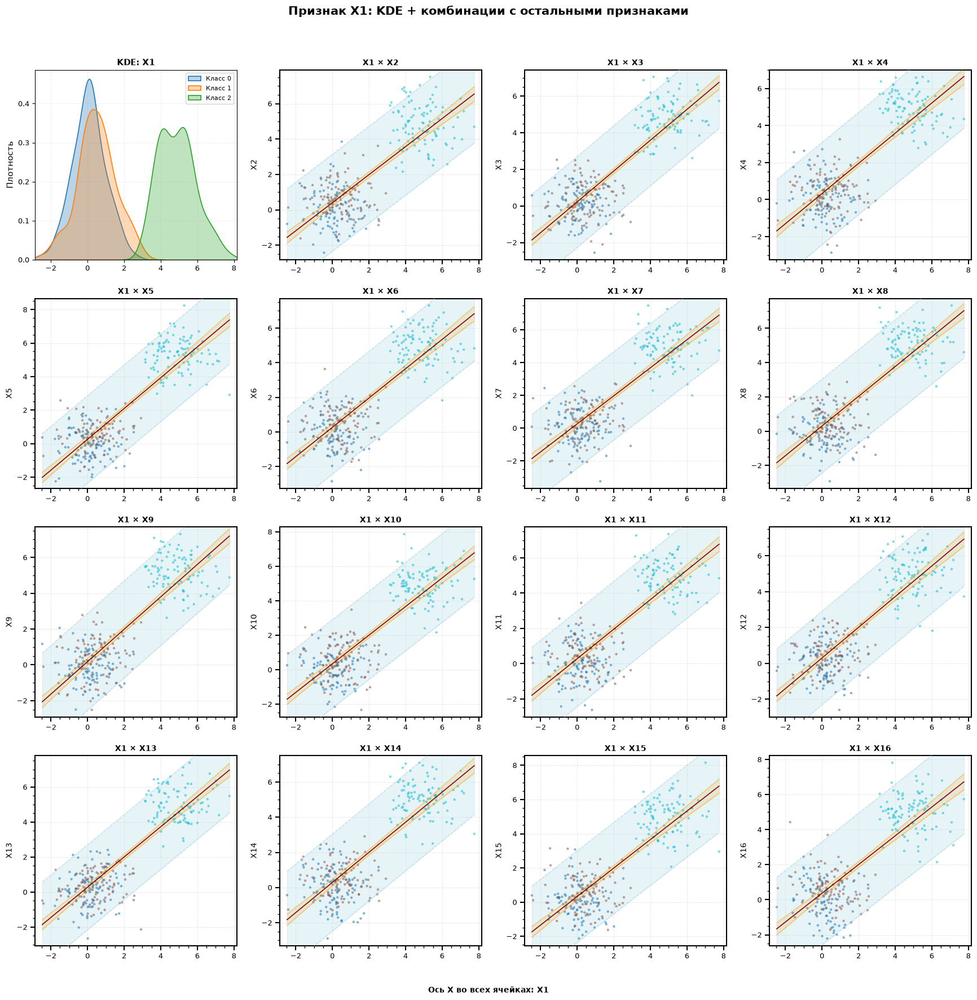

панно признака X1  (15 комбинаций + KDE)


In [63]:
plot_feature_combinations_panel(
    df1, "X1",
    subplot_size=3.8, scale_mode="per_feature",
    show_confidence_band=True, show_prediction_interval=True,
    point_size=10, point_alpha=0.55, show_grid=True,
)

### [3.2] Генерация дополнительных датасетов

На основе созданного в пункте [3.1] датасета `df1` сгенерировать отдельные дополнительные датасеты (`dfrX`), в которых объекты одного класса (который имеет пересечение с другим) повторены X раз (X = 1, 2, 5, 10, 100, 1000 раз, с учетом исходного), а количество объектов в остальных классах оставлено неизменным.

Отдельно для датасетов `dfrX` восстановить в таблицу координаты следующих точек:
- центры масс каждого класса;
- общий центр масс выбранных классов;
- центр отрезка, соединяющего центры масс выбранных классов.

In [64]:
datasets = {}
repeat_data = [1,2,5,10,100,1000]

class0 = df1[df1['class'] == 0].copy()
class1 = df1[df1['class'] == 1].copy()
class2 = df1[df1['class'] == 2].copy()

for count in repeat_data:
    repeated_class0 = pd.concat([class0] * count, ignore_index=True)
    dfr = pd.concat([repeated_class0, class1, class2], ignore_index=True)
    
    # готовый датасет
    dfr = dfr.sample(frac=1, random_state=42).reset_index(drop=True)

    # вычисляем точки
    class_centers = dfr.groupby('class')[features].mean()
    class0_center = class_centers.iloc[0].to_numpy() # центр масс класс=0
    class1_center = class_centers.iloc[1].to_numpy() # центр масс класс=1
    class2_center = class_centers.iloc[2].to_numpy() # центр масс класс=2
            
    selected_01 = dfr[dfr['class'].isin([0, 1])][features].mean().to_numpy() # центр масс класс 0 и 1
    selected_02 = dfr[dfr['class'].isin([0, 2])][features].mean().to_numpy() # центр масс класс 0 и 2
    selected_12 = dfr[dfr['class'].isin([1, 2])][features].mean().to_numpy() # центр масс класс 1 и 2

    midpoint_01 = (class0_center + class1_center) / 2 # середина отрезка между 0 и 1
    midpoint_02 = (class0_center + class2_center) / 2 # середина отрезка между 0 и 2
    midpoint_12 = (class1_center + class2_center) / 2 # середина отрезка между 1 и 2

    datasets[f'dfr{count}'] = {
        'data': dfr, 
        'center_mass': [class0_center, class1_center, class2_center],
        'pairs_certer': [selected_01, selected_02, selected_12],
        'midpoints': [midpoint_01, midpoint_02, midpoint_12] 
    }
    print(f'dfr{count}: размер {dfr.shape[0]}')
    #print(f'\tЦентры масс:\n\t\tКласс 1: {class1_center}\n\t\tКласс 2: {class2_center}\n\t\tКласс 3: {class3_center}')
    #print(f'\tЦентры масс - объединенный: {overall_center}')
    #print(f'\tЦентральная точка отрезка: {midpoint}')
    #print("="*60)
    #print()

dfr1: размер 300
dfr2: размер 400
dfr5: размер 700
dfr10: размер 1200
dfr100: размер 10200
dfr1000: размер 100200


In [85]:
import re
from itertools import combinations as _comb

def plot_class_centers(
    datasets,
    features,
    classes,                 # исследуемая пара/набор меток, напр. (0,1), (0,2), (1,2)
    class_col="class",
    *,
    extra_classes=None,      # классы-фон (рисуются точками, без центров/отрезка), напр. (1,)
    colors=None,             # цвета по ПОЗИЦИИ в classes; None = tab10
    extra_color="0.75", extra_alpha=0.4,
    ncols=3, cell_w=4.9, cell_h=5.5,
    point_size=15, point_alpha=0.4,
    center_size=180, center_lw=1.2,
    seg_color="black", seg_lw=2,
    mid_color="red", mid_size=110,
    joint_color="magenta", joint_size=250,
    x_feat=None, y_feat=None,        # признаки для осей (None = features[0], features[1])
    title_fs=13, legend_fs=10,
    legend_ncol=None,        # колонок в ОБЩЕЙ легенде; None = авто (<=6)
    suptitle=None, save_path=None, file_dpi=200,
):
    classes = list(classes)
    extra_classes = [] if extra_classes is None else list(extra_classes)
    xf = features[0] if x_feat is None else x_feat
    yf = features[1] if y_feat is None else y_feat

    # порядок всех меток -> позиция метки в center_mass и индекс пары в pairs_certer/midpoints
    all_cls = sorted(datasets[next(iter(datasets))]["data"][class_col].unique())
    pos = {c: i for i, c in enumerate(all_cls)}
    pair_idx = {tuple(p): i for i, p in enumerate(_comb(all_cls, 2))}

    if colors is None:
        cmap_tab = plt.get_cmap("tab10")
        colors = [cmap_tab(i % 10) for i in range(max(len(classes), 1))]
    cls_color = {c: colors[i] for i, c in enumerate(classes)}

    n = len(datasets)
    nrows = int(np.ceil(n / ncols))
    fig_h = nrows * cell_h
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * cell_w, fig_h), squeeze=False)
    axes = axes.ravel()

    for i, (name, dataset) in enumerate(datasets.items()):
        ax = axes[i]
        dfr = dataset["data"]
        cm = dataset["center_mass"]      # позиции == all_cls
        pc = dataset["pairs_certer"]     # индексы == pair_idx
        mp = dataset["midpoints"]

        # --- точки исследуемых классов ---
        for cls in classes:
            sub = dfr[dfr[class_col] == cls]
            ax.scatter(sub[xf], sub[yf], color=cls_color[cls], alpha=point_alpha,
                       s=point_size, label=f"Класс {cls} (n={len(sub)})")
        # --- классы-фон (если заданы) ---
        for cls in extra_classes:
            sub = dfr[dfr[class_col] == cls]
            ax.scatter(sub[xf], sub[yf], color=extra_color, alpha=extra_alpha,
                       s=point_size, label=f"Класс {cls} (фон, n={len(sub)})")

        # --- центры масс исследуемых классов ---
        for cls in classes:
            ctr = cm[pos[cls]]
            ax.scatter(ctr[0], ctr[1], color=cls_color[cls], marker="X", s=center_size,
                       edgecolors="black", linewidths=center_lw, zorder=5,
                       label=f"Центр масс класса {cls}")

        # --- отрезок / середина / общий центр между первыми двумя классами ---
        if len(classes) >= 2:
            a, b = classes[0], classes[1]
            ca, cb = cm[pos[a]], cm[pos[b]]
            k = pair_idx[(a, b)] if (a, b) in pair_idx else pair_idx[(b, a)]
            ax.plot([ca[0], cb[0]], [ca[1], cb[1]], color=seg_color, ls="--",
                    lw=seg_lw, label=f"Отрезок {a}–{b}")
            md = mp[k]
            ax.scatter(md[0], md[1], color=mid_color, marker="D", s=mid_size,
                       edgecolors="black", zorder=7, label=f"Середина отрезка {a}–{b}")
            jc = pc[k]
            ax.scatter(jc[0], jc[1], color=joint_color, marker="*", s=joint_size,
                       edgecolors="black", zorder=8, label=f"Общий центр масс {a} и {b}")

        ax.set_title(f"{name} (n={len(dfr)})", fontsize=title_fs)   # общее n датасета — в заголовке
        ax.set_xlabel(xf); ax.set_ylabel(yf)
        ax.grid(alpha=0.3)
        # >>> ax.legend(...) УБРАН: легенда теперь одна общая, ниже <<<

    for ax in axes[n:]:
        ax.axis("off")

    if suptitle is None:
        suptitle = f"Центры масс · классы={classes}" + (f" (+фон {extra_classes})" if extra_classes else "")
    fig.suptitle(suptitle, fontsize=title_fs + 2, fontweight="bold", y=1.0)

    # ================= ОБЩАЯ ЛЕГЕНДА ВНИЗУ ВСЕГО ПАННО =================
    h, l = axes[0].get_legend_handles_labels()          # стили/цвета — ровно как нарисовано
    l_clean = [re.sub(r"\s*\(n=\d+\)", "", s) for s in l]   # убрать датасет-специфичное n
    ncol_leg = legend_ncol if legend_ncol else max(1, min(len(l_clean), 6))
    n_rows_leg = int(np.ceil(len(l_clean) / ncol_leg))
    leg_row_h_in = (legend_fs * 1.6 + 6.0) / 72.0       # примерная высота строки легенды, дюймы
    bottom_frac = n_rows_leg * leg_row_h_in / fig_h + 0.012   # доля высоты под легенду + пад

    fig.legend(h, l_clean, loc="lower center", ncol=ncol_leg,
               fontsize=legend_fs, frameon=True, framealpha=0.9,
               borderaxespad=0.4, bbox_to_anchor=(0.5, 0.004))

    plt.tight_layout(rect=(0, bottom_frac, 1, 0.99))    # освобождаем снизу место под легенду

    if save_path:
        fig.savefig(save_path, dpi=file_dpi, bbox_inches="tight")  # tight подстрахует вылезание
        print(f"Сохранено: {save_path} (dpi={file_dpi})")
    plt.show()

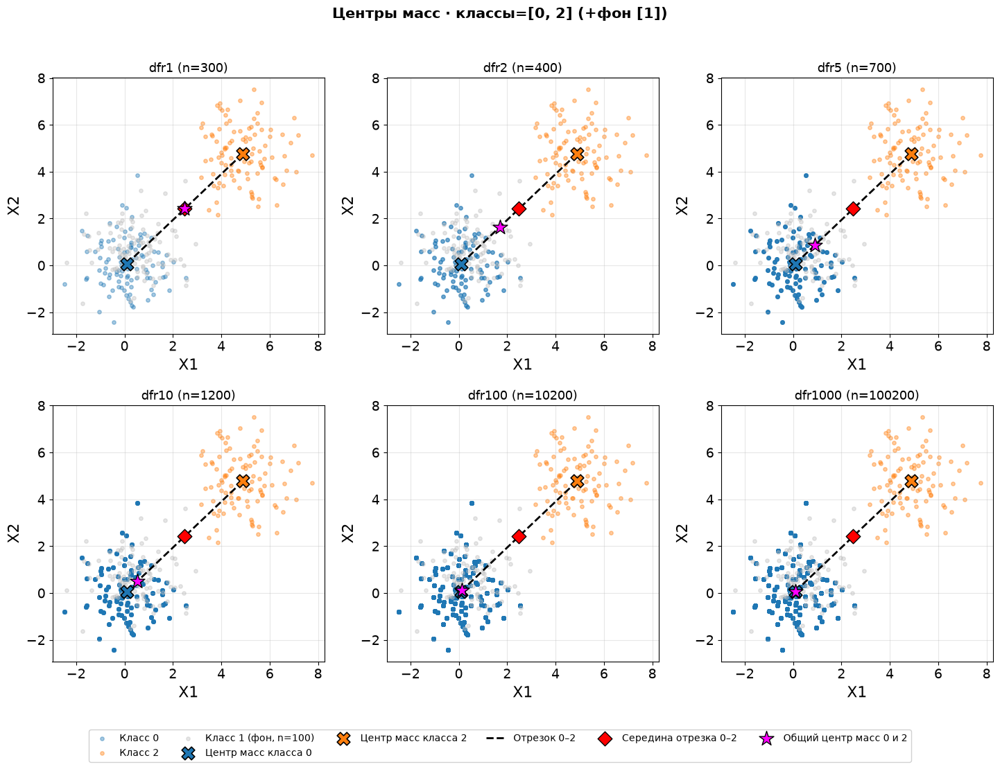

In [86]:
plot_class_centers(datasets, features, classes=(0, 2), extra_classes=(1,))

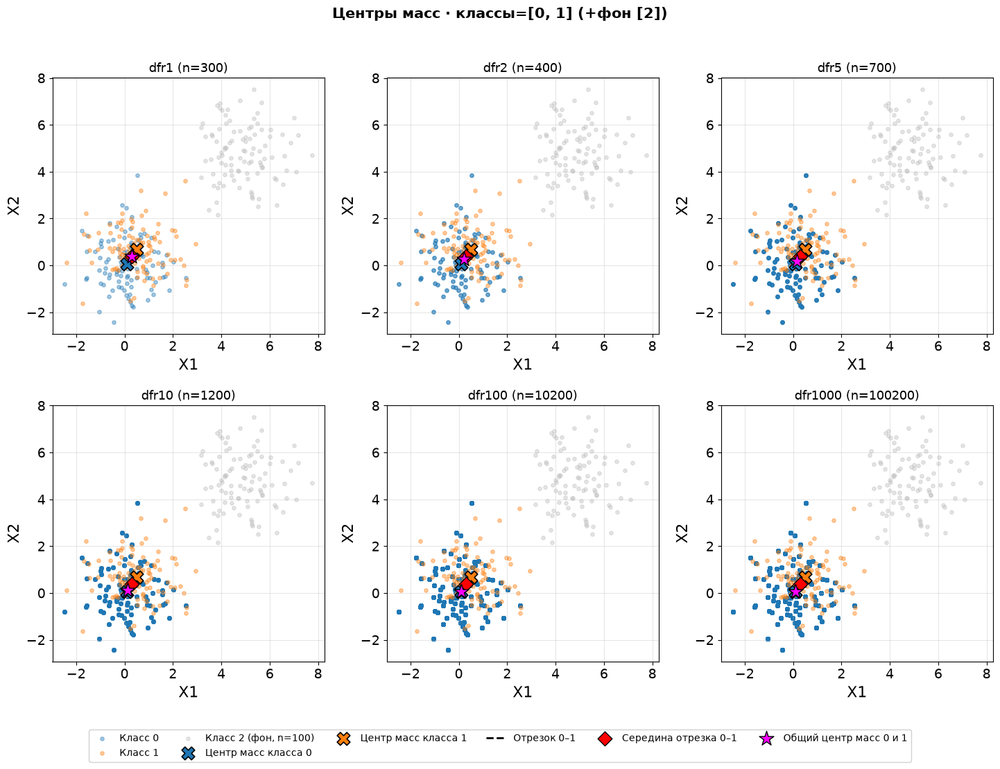

In [87]:
plot_class_centers(datasets, features, classes=(0, 1), extra_classes=(2,))

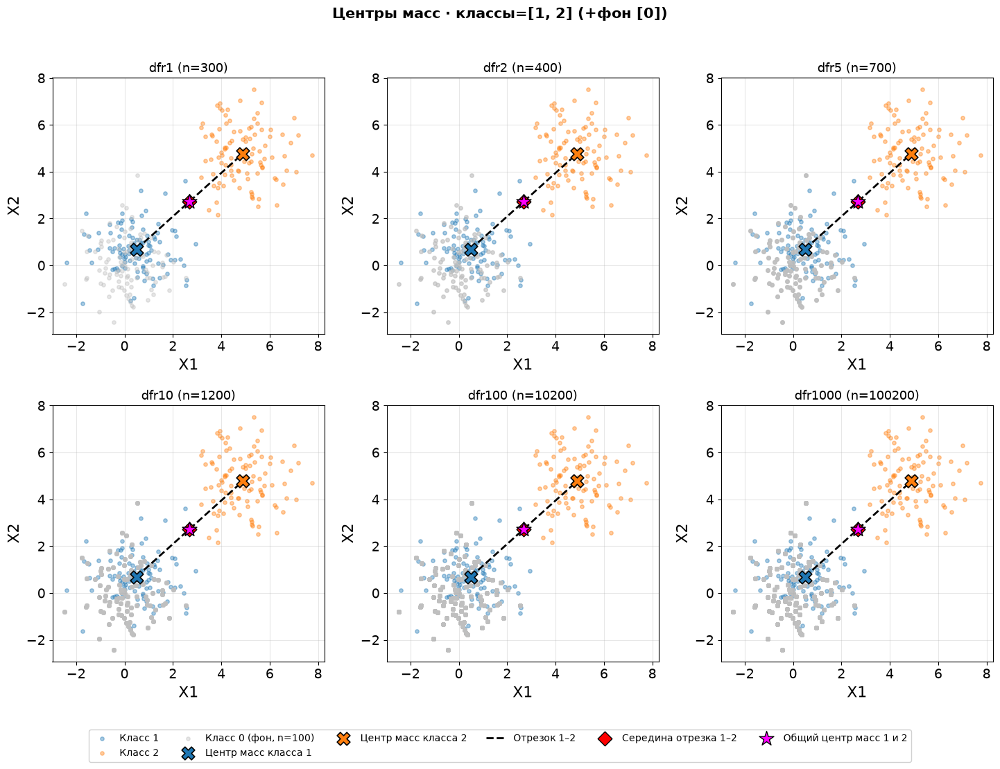

In [88]:
plot_class_centers(datasets, features, classes=(1, 2), extra_classes=(0,))

### [3.3] Использование алгоритмов на выборке

Выбрать пару классов (включая класс с повторенными объектами) и пару количественных признаков, определить в паре целевой класс. Используя методы LDA, QDA, Gaussian Naïve Bayes, MDC для каждого из сформированных датасетов `dfrX`, графически в виде панно X (датасет `dfrX`) на Y (метод) для каждой пары датасет-алгоритм построить индивидуальные графики с решающей функцией, разграниченные решающей линией решающей функции зоны и отдельные объекты классов.

Визуализацию выполнять с отображением положения центров масс и соединяющего центры масс классов отрезок с его центральной точкой на каждом графике.

In [69]:
from matplotlib.colors import ListedColormap
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB

# MDC: использует готовые центры классов
class MDC:
    def __init__(self, centers, class_labels=None):
        self.centers = np.asarray(centers)
        self.class_labels = None if class_labels is None else np.asarray(class_labels)

    def fit(self, X, y):
        # порядок столбцов центров == порядок self.classes_;
        if self.class_labels is not None:
            self.classes_ = self.class_labels
        else:
            self.classes_ = np.array(sorted(np.unique(np.asarray(y))))
        return self

    def predict(self, X):
        distances = np.linalg.norm(
            np.asarray(X)[:, None, :] - self.centers[None, :, :],
            axis=2
        )
        idx = np.argmin(distances, axis=1)
        return self.classes_[idx]         

    def predict_proba(self, X):
        distances = np.linalg.norm(
            np.asarray(X)[:, None, :] - self.centers[None, :, :],
            axis=2
        )
        # Чем меньше расстояние до центра, тем выше оценка класса
        scores = -distances
        scores -= scores.max(axis=1, keepdims=True)
        exp_scores = np.exp(scores)
        return exp_scores / exp_scores.sum(axis=1, keepdims=True)

    def decision_score(self, X):
        distances = np.linalg.norm(
            np.asarray(X)[:, None, :] - self.centers[None, :, :],
            axis=2
        )
        # Положительная оценка означает близость к классу 2
        return distances[:, 0] - distances[:, 1]

def plot_diff_methods(target_class, classes, cols, datasets,
                      *, model_factory=None, seed=123):          
    """Панно границ решений для любой пары классов/колонок и ЛЮБОГО набора моделей."""
    classes = sorted(classes)                                     
    if model_factory is None:                                     
        def model_factory(X, y, centers, seed):
            return {'LDA': LinearDiscriminantAnalysis(),
                    'QDA': QuadraticDiscriminantAnalysis(),
                    'GNB': GaussianNB(),
                    'MDC': MDC(centers, class_labels=classes),}

    names = list(model_factory(None, None, None, seed).keys())    
    nrows, ncols = len(datasets), len(names)                      
    fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 5*nrows), squeeze=False)
    cmap = ListedColormap(['#b3d9ff', '#ffdab3'])

    for i, (name, dataset) in enumerate(datasets.items()):
        df = dataset['data']; df = df[df['class'].isin(classes)]
        X = df[cols].values; y = df['class'].values
        centers = df.groupby('class')[cols].mean().loc[classes].to_numpy()
        midpoint = centers.mean(axis=0)
        labs = np.unique(y)
        inner = (labs[:-1] + labs[1:]) / 2.0
        edges = np.concatenate(([labs[0]-0.5], inner, [labs[-1]+0.5]))

        models = model_factory(X, y, centers, seed)               
        xx, yy = np.meshgrid(np.linspace(X[:,0].min()-1, X[:,0].max()+1, 200),
                             np.linspace(X[:,1].min()-1, X[:,1].max()+1, 200))
        grid = np.c_[xx.ravel(), yy.ravel()]

        for j, model_name in enumerate(names):                   
            ax = axes[i, j]
            model = models[model_name].fit(X, y)
            Z = model.predict(grid).reshape(xx.shape)
            ax.contourf(xx, yy, Z, levels=edges, cmap=cmap, alpha=0.6)
            ax.contour(xx, yy, Z, levels=inner, colors='black', linewidths=1.5)
            for k, (cls, color) in enumerate(zip(classes, ['blue','orange'])):
                p = X[y==cls]
                ax.scatter(p[:,0], p[:,1], c=color, s=12,
                           alpha=0.25 if k==0 else 0.5,
                           label=f'Класс {cls} (n={len(p)})' if j==0 else '_nolegend_')
            for cls, ctr, color in zip(classes, centers, ['blue','orange']):
                ax.scatter(*ctr, c=color, marker='X', s=150, edgecolors='black', zorder=5, label=f'Центр {cls}')
            ax.plot(centers[:,0], centers[:,1], 'r--', lw=2, label='Отрезок')
            ax.scatter(*midpoint, c='red', marker='D', s=80, edgecolors='black', zorder=6, label='Середина')
            ax.set_title(f'{name} | {model_name}'); ax.set_xlabel(cols[0]); ax.set_ylabel(cols[1])
            if j == 0: ax.legend(fontsize=10, loc='upper left')
            ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()

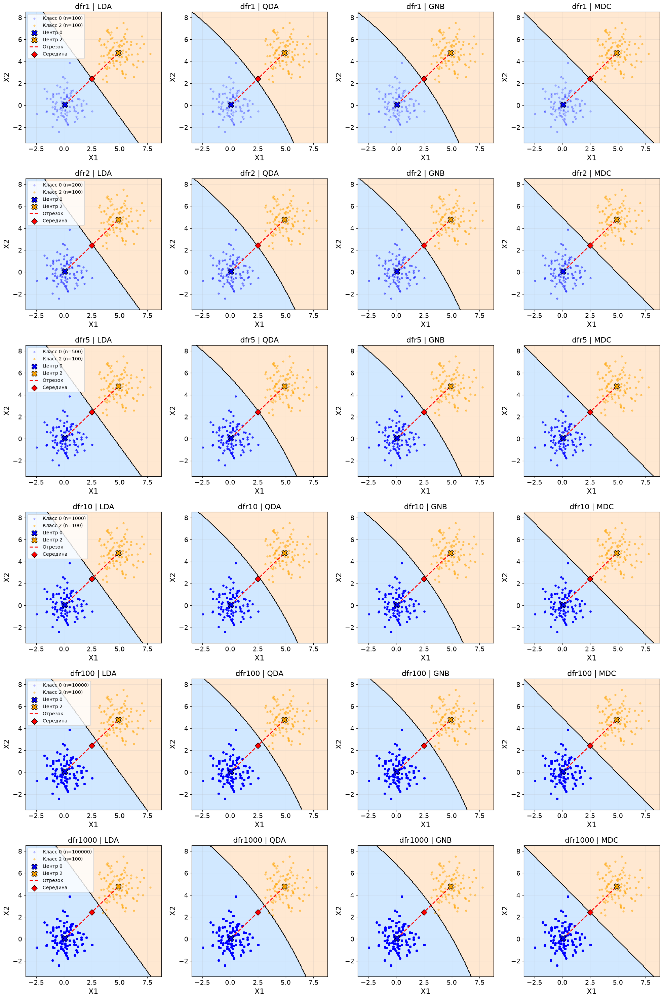

In [70]:
# Параметры
classes_1 = [0, 2]
target_class_1 = 0
cols = ['X1', 'X2']

plot_diff_methods(target_class=target_class_1, classes=classes_1, cols=cols, datasets=datasets)

### [3.4] Анализ результатов с помощью ROC и PR кривых

Для каждого из решений из пункта [3.3] оценить качество работы полученных на основе LDA классификаторов, используя ROC и PR кривые и восстановив на графике кривых соответствующие каждому решению 95% доверительные полосы (Confidence bands 95%) ROC кривой бутстрепом (n = 100 или больше). Для каждой кривой численно также отобразить метрику AUROC и ее доверительные интервалы CI95. Отдельно вывести графики сравнения ROC кривых всех классификаторов — LDA, QDA, GNB, MDC.

Все полученные графики возможно расположить в четыре колонки:
- левая колонка – визуализация пространства и решений LDA для отдельного `dfrX`;
- следующая – соответствующий этому `dfrX` и LDA AUROC с доверительной полосой и бутстреп линиями на одном рисунке;
- следующая – соответствующий этому `dfrX` и LDA AUPRC с доверительной полосой и бутстреп линиями на одном рисунке;
- правая – соответствующие этому `dfrX` графики с ROC кривой для всех классификаторов LDA, QDA, GNB, MDC и их доверительными полосами на одном рисунке (без отображения линий бутстрепа).

In [71]:
def run_lda_eval(datasets, features, classes, target_class, cols,
                 n_boot=200, n_fan=60, grid=200, seed=123,
                 figsize=None, suptitle=None,
                 *, hero='LDA', model_factory=None, colors=None, styles=None):   

    from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score
    
    classes = sorted(classes)                                                     
    COL_IDX = [features.index(c) for c in cols]
    rng = np.random.default_rng(seed)

    if model_factory is None:                                                     
        def model_factory(X, y, centers, seed):
            return {'LDA': LinearDiscriminantAnalysis(),
                    'QDA': QuadraticDiscriminantAnalysis(),
                    'GNB': GaussianNB(),
                    'MDC': MDC(centers)}
    if colors is None:                                                            
        colors = {'LDA':'#1f77b4','QDA':'#ff7f0e','GNB':'#2ca02c','MDC':'#d62728'}
    if styles is None:                                                            
        styles = {'LDA':'-','QDA':'--','GNB':'-.','MDC':':'}

    def _get_score(model, X):
        proba = model.predict_proba(X); cl = list(getattr(model,'classes_',[0,1]))
        return proba[:, cl.index(target_class) if target_class in cl else 0]

    def _auc_trapz(fpr, tpr):
        f = np.asarray(fpr,float); t = np.asarray(tpr,float)
        integ = getattr(np,"trapezoid",None) or getattr(np,"trapz",None)
        return float(integ(t,f))

    def _clean_monotone(x, y):
        o = np.lexsort((-y,x)); xs,ys = x[o],y[o]; ux,fi = np.unique(xs,return_index=True); return ux,ys[fi]

    def _bootstrap_curves(y, score, kind):                                        # closure над target_class — модель-агностик
        y=np.asarray(y); score=np.asarray(score,float); n=len(y); xg=np.linspace(0,1,grid)
        if kind=='roc':
            fpr_c,tpr_c,_=roc_curve(y,score,pos_label=target_class); metric_c=_auc_trapz(fpr_c,tpr_c)
            x_raw,y_raw=fpr_c,tpr_c; fx,ty=_clean_monotone(fpr_c,tpr_c); yc=np.interp(xg,fx,ty)
        else:
            prec,rec,_=precision_recall_curve(y,score,pos_label=target_class); rec,prec=rec[::-1],prec[::-1]
            metric_c=average_precision_score(y,score,pos_label=target_class)
            x_raw,y_raw=rec,prec; rx,py=_clean_monotone(rec,prec); yc=np.interp(xg,rx,py)
        rows,mets=[],[]
        for _ in range(n_boot):
            idx=rng.integers(0,n,size=n); yb,sb=y[idx],score[idx]
            if np.unique(yb).size<2: continue
            if kind=='roc':
                fb,tb,_=roc_curve(yb,sb,pos_label=target_class); fb,tb=_clean_monotone(fb,tb)
                rows.append(np.interp(xg,fb,tb)); mets.append(_auc_trapz(fb,tb))
            else:
                pb,rb,_=precision_recall_curve(yb,sb,pos_label=target_class); rb,pb=rb[::-1],pb[::-1]; rb,pb=_clean_monotone(rb,pb)
                rows.append(np.interp(xg,rb,pb)); mets.append(average_precision_score(yb,sb,pos_label=target_class))
        mat=np.vstack(rows) if rows else np.empty((0,grid)); mets=np.array(mets)
        lo=np.percentile(mat,2.5,axis=0) if mat.size else np.full(grid,np.nan)
        hi=np.percentile(mat,97.5,axis=0) if mat.size else np.full(grid,np.nan)
        mci=((np.nanpercentile(mets,2.5),np.nanpercentile(mets,97.5)) if mets.size else (np.nan,np.nan))
        return dict(xg=xg,yc=yc,lo=lo,hi=hi,mat=mat,x_raw=x_raw,y_raw=y_raw,metric=metric_c,mci=mci)

    def _draw_roc_pr(ax,d,kind,title,show_fan,color,pi):
        ly='TPR' if kind=='roc' else 'Precision'; lx='FPR' if kind=='roc' else 'Recall'
        if show_fan and d['mat'].shape[0]:
            step=max(1,d['mat'].shape[0]//n_fan)
            for row in d['mat'][::step]: ax.plot(d['xg'],row,color=color,alpha=0.10,lw=0.6,zorder=2)
        ax.fill_between(d['xg'],d['lo'],d['hi'],color=color,alpha=0.20,zorder=3,label='95% CI (bootstrap)')
        ax.plot(d['x_raw'],d['y_raw'],color=color,lw=2.4,zorder=5,label='точечная кривая')
        if kind=='roc': ax.plot([0,1],[0,1],ls='--',color='gray',lw=1,zorder=1,label='baseline')
        else: ax.axhline(pi,color='gray',ls='--',lw=1,zorder=1,label=f'baseline π={pi:.3f}')
        ax.set_xlim(0,1); ax.set_ylim(0,1); ax.set_xlabel(lx); ax.set_ylabel(ly)
        ax.set_title(f"{title}\n{('AUROC' if kind=='roc' else 'AUPRC')}={d['metric']:.3f} "
                     f"[CI95: {d['mci'][0]:.3f}, {d['mci'][1]:.3f}]",fontsize=10)
        ax.legend(fontsize=9,loc='lower right'); ax.grid(alpha=0.2)

    def _draw_space(ax, ds, model):                                               
        df=ds['data']; df=df[df['class'].isin(classes)]
        X=df[cols].values; y=df['class'].values
        centers=np.array(ds['center_mass'])[classes][:,COL_IDX]; mid=(centers[0]+centers[1])/2.0
        labs=np.unique(y); inner=(labs[:-1]+labs[1:])/2.0                          
        edges=np.concatenate(([labs[0]-0.5],inner,[labs[-1]+0.5]))
        xx,yy=np.meshgrid(np.linspace(X[:,0].min()-1,X[:,0].max()+1,200),
                          np.linspace(X[:,1].min()-1,X[:,1].max()+1,200))
        Z=model.predict(np.c_[xx.ravel(),yy.ravel()]).reshape(xx.shape)
        cmap=ListedColormap(['#b3d9ff','#ffdab3'][:len(labs)])
        ax.contourf(xx,yy,Z,levels=edges,cmap=cmap,alpha=0.6)
        ax.contour(xx,yy,Z,levels=inner,colors='black',linewidths=1.5)
        for cls,c in zip(classes,['blue','orange']):
            p=X[y==cls]; ax.scatter(p[:,0],p[:,1],c=c,s=10,alpha=0.3,label=f'Класс {cls}')
        for cls,ctr,c in zip(classes,centers,['blue','orange']):
            ax.scatter(*ctr,c=c,marker='X',s=150,edgecolors='black',zorder=6,label=f'Центр {cls}')
        ax.plot(centers[:,0],centers[:,1],'r--',lw=2,label='Отрезок')
        ax.scatter(*mid,c='red',marker='D',s=90,edgecolors='black',zorder=7,label='Середина')
        ax.set_xlabel(cols[0]); ax.set_ylabel(cols[1])
        ax.legend(fontsize=9,loc='upper left'); ax.grid(alpha=0.2)

    names=list(model_factory(None,None,None,seed).keys())                          
    n_rows=len(datasets)
    if figsize is None: figsize=(24,6*n_rows)
    fig,axes=plt.subplots(n_rows,4,figsize=figsize,squeeze=False)

    for i,(name,ds) in enumerate(datasets.items()):
        df=ds['data']; df=df[df['class'].isin(classes)]
        X=df[cols].values; y=df['class'].values; pi_ds=float((y==target_class).mean())
        centers=np.array(ds['center_mass'])[classes][:,COL_IDX]
        models={m:mdl.fit(X,y) for m,mdl in model_factory(X,y,centers,seed).items()}   

        _draw_space(axes[i,0], ds, models[hero])                                  
        axes[i,0].set_title(f'{name} | {hero} (пространство)',fontsize=11)

        s_hero=_get_score(models[hero],X)                                          
        _draw_roc_pr(axes[i,1],_bootstrap_curves(y,s_hero,'roc'),'roc',f'{name} | {hero} ROC',True,colors[hero],pi_ds)
        _draw_roc_pr(axes[i,2],_bootstrap_curves(y,s_hero,'pr'),'pr',f'{name} | {hero} PR',True,colors[hero],pi_ds)

        ax=axes[i,3]                                                               
        for mname,mdl in models.items():
            dm=_bootstrap_curves(y,_get_score(mdl,X),'roc')
            ax.fill_between(dm['xg'],dm['lo'],dm['hi'],color=colors[mname],alpha=0.12,zorder=2)
            ax.plot(dm['x_raw'],dm['y_raw'],color=colors[mname],lw=2,linestyle=styles[mname],zorder=4,
                    label=f"{mname} AUROC={dm['metric']:.3f}")
        ax.plot([0,1],[0,1],ls='--',color='gray',lw=1,zorder=1,label='baseline')
        ax.set_xlim(0,1); ax.set_ylim(0,1); ax.set_xlabel('FPR'); ax.set_ylabel('TPR')
        ax.set_title(f'{name} | ROC: {" / ".join(names)} (95% полосы)',fontsize=11)
        ax.legend(fontsize=9,loc='lower right'); ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

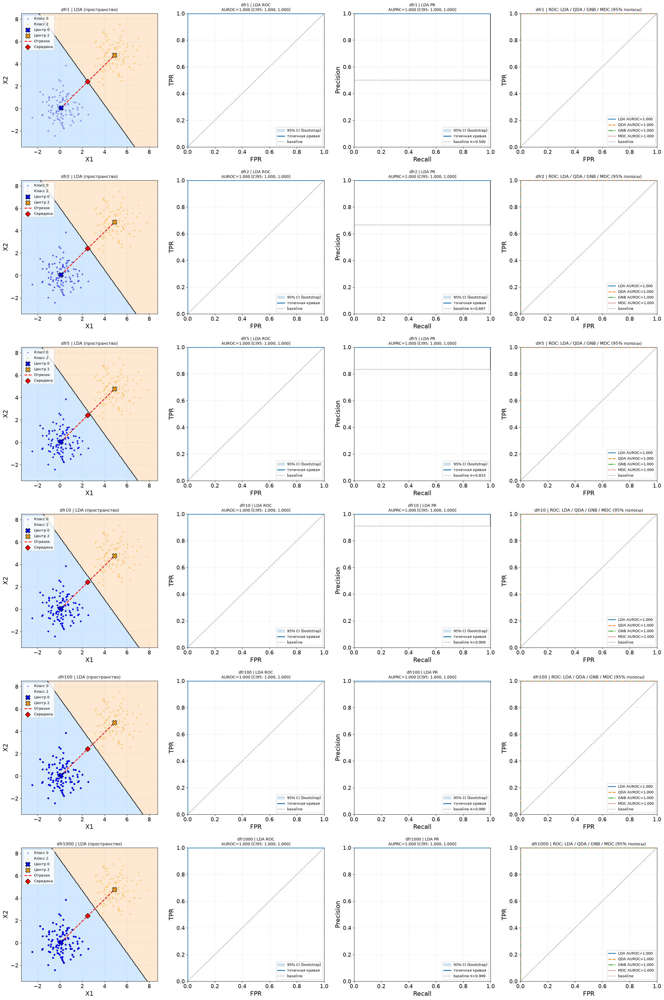

In [72]:
run_lda_eval(datasets, features, classes_1, target_class_1, cols)

### [3.5]

Выбрать другой целевой класс и повторить визуализации пунктов [3.3–3.4].

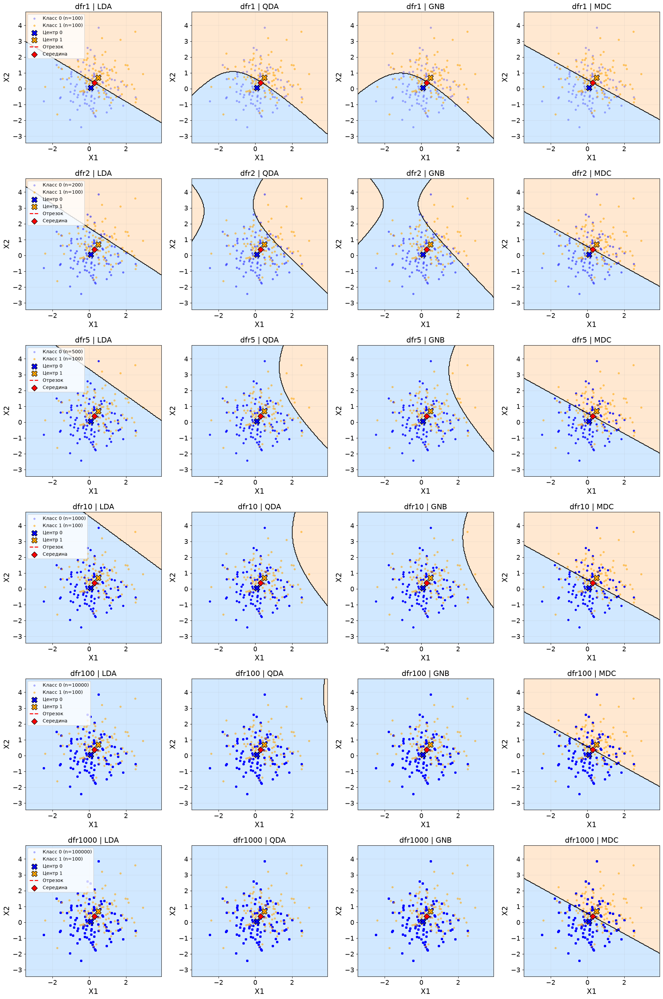

In [73]:
# Параметры
classes_2 = [0, 1]
target_class_2 = 0
cols = ['X1', 'X2']

plot_diff_methods(target_class=target_class_2, classes=classes_2, cols=cols, datasets=datasets)

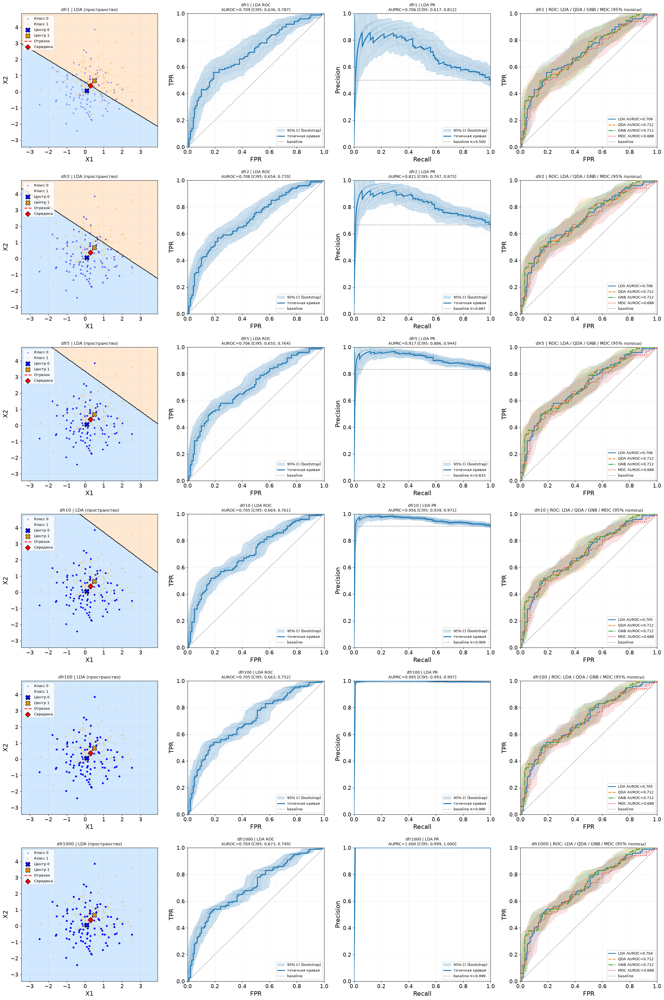

In [74]:
run_lda_eval(datasets, features, classes_2, target_class_2, cols)

### [3.6]

Для датасета `dfr10` на основе 3-fold, 5-fold, 10-fold, 20-fold, 50-fold, 100-fold кросс-валидации построить кривые AUROC и AUPRC с 95% доверительными полосами (CI95), выведя каждую кривую AUROC и AUPRC со всеми линиями кросс-валидации и с 95% доверительными полосами (CI95) как отдельный график.

Вместо CI95 можно взять CI90, CI80 или другой квантиль доверительной полосы.

In [75]:
from sklearn.model_selection import StratifiedKFold
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score


def plot_cv_roc(
    datasets,
    dataset_key="dfr10",
    class_col="class",
    classes=(0, 1),
    target_class=1,
    cols=("X1", "X2"),
    k_list=(3, 5, 10, 20, 50, 100),
    conf=0.95,
    grid=200,
    seed=123,
    save_path=None,
    file_dpi=200,
):
    CW, CH = 5.2, 5.2          
    MX, MY = 1.0, 1.8          
    LINE = "#b44c1f"
    SPACE = "#1f69b4"

    FAN_A, FAN_LW = 0.1, 0.5
    BAND_A, CURVE_LW, BASE_LW = 0.22, 2.4, 1.2
    FS_TITLE, FS_AXIS, FS_LEG = 11, 11, 9

    df = datasets[dataset_key]["data"]
    df = df[df[class_col].isin(list(classes))].reset_index(drop=True)
    X = df[list(cols)].to_numpy(dtype=float)
    y = df[class_col].to_numpy()
    pi_ds = float((y == target_class).mean())
    alpha = (1.0 - conf) / 2.0
    xg = np.linspace(0.0, 1.0, grid)

    def _mono(x, yy):
        o = np.lexsort((-yy, x)); xs, ys = x[o], yy[o]
        ux, fi = np.unique(xs, return_index=True)
        return ux, ys[fi]

    def _auc_trapz(fpr, tpr):                 
        f = np.asarray(fpr, float); t = np.asarray(tpr, float)
        return float(np.sum((f[1:] - f[:-1]) * (t[1:] + t[:-1]) / 2.0))

    def _score(model, Xpart):
        proba = model.predict_proba(Xpart)
        cl = list(getattr(model, "classes_", [0, 1]))
        return proba[:, cl.index(target_class) if target_class in cl else 0]

    def _run_cv(k):                           
        skf = StratifiedKFold(n_splits=k, shuffle=True, random_state=seed)
        roc_rows, pr_rows, roc_m, pr_m = [], [], [], []
        for tr, te in skf.split(X, y):
            yt = y[te]
            if np.unique(yt).size < 2:     
                continue
            s = _score(LinearDiscriminantAnalysis().fit(X[tr], y[tr]), X[te])
            fpr, tpr, _ = roc_curve(yt, s, pos_label=target_class)
            fpr, tpr = _mono(fpr, tpr)
            roc_rows.append(np.interp(xg, fpr, tpr)); roc_m.append(_auc_trapz(fpr, tpr))
            prec, rec, _ = precision_recall_curve(yt, s, pos_label=target_class)
            rec, prec = rec[::-1], prec[::-1]
            rec, prec = _mono(rec, prec)
            pr_rows.append(np.interp(xg, rec, prec))
            pr_m.append(average_precision_score(yt, s, pos_label=target_class))
        return np.array(roc_rows), np.array(pr_rows), np.array(roc_m), np.array(pr_m)

    def _draw(ax, rows, mets, kind, k):        # одна ячейка панно
        lbl_x, lbl_y = ("FPR", "TPR") if kind == "roc" else ("Recall", "Precision")
        mname = "AUROC" if kind == "roc" else "AUPRC"
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_xlabel(lbl_x, fontsize=FS_AXIS)
        ax.set_ylabel(lbl_y, fontsize=FS_AXIS)
        ax.grid(alpha=0.2, ls="--")
        
        for r in rows:                         # линии кросс-валидации
            ax.plot(xg, r, color=LINE, alpha=FAN_A, lw=FAN_LW, zorder=2)
        lo = np.percentile(rows, 100 * alpha, axis=0)
        hi = np.percentile(rows, 100 * (1 - alpha), axis=0)
        ax.fill_between(xg, lo, hi, color=SPACE, alpha=BAND_A, zorder=3,
                        label=f"CI{conf*100:.0f} (фолды)")
        ax.plot(xg, rows.mean(axis=0), color=LINE, lw=CURVE_LW, zorder=5, label="средняя CV")
        if kind == "roc":
            ax.plot([0, 1], [0, 1], ls="--", color="gray", lw=BASE_LW, zorder=1, label="baseline")
        else:
            ax.axhline(pi_ds, ls="--", color="gray", lw=BASE_LW, zorder=1, label=f"π={pi_ds:.3f}")
        m = float(np.mean(mets))
        m_lo = float(np.percentile(mets, 100 * alpha))
        m_hi = float(np.percentile(mets, 100 * (1 - alpha)))
        ax.set_title(f"k={k} · {mname}={m:.3f} [CI{conf*100:.0f}: {m_lo:.3f},{m_hi:.3f}] · фолд={len(rows)}",
                     fontsize=FS_TITLE, fontweight="bold")
        ax.legend(loc="lower right", fontsize=FS_LEG, framealpha=0.9)

    # ---- кэш: каждый k один раз (ROC и PR из одного прохода CV, фолды согласованы) ----
    cache = {k: _run_cv(k) for k in k_list}

    # ---- один холст: строки = k, колонки = [ROC | PR]; figsize авто от len(k_list) ----
    nrows, ncols = len(k_list), 2
    fig, axes = plt.subplots(
        nrows, ncols,
        figsize=(ncols * CW + MX, nrows * CH + MY),
        squeeze=False,
    )
    for i, k in enumerate(k_list):
        roc_rows, pr_rows, roc_m, pr_m = cache[k]
        _draw(axes[i, 0], roc_rows, roc_m, "roc", k)
        _draw(axes[i, 1], pr_rows, pr_m, "pr", k)

    fig.suptitle(
        f"LDA на паре {tuple(cols)}, target={target_class}",
        fontsize=FS_TITLE + 3, fontweight="bold", y=0.999,
    )
    plt.tight_layout(rect=(0, 0, 1, 0.985))
    if save_path:
        fig.savefig(save_path, dpi=file_dpi, bbox_inches="tight")
        print(f"Сохранено: {save_path} (dpi={file_dpi})")
    plt.show()

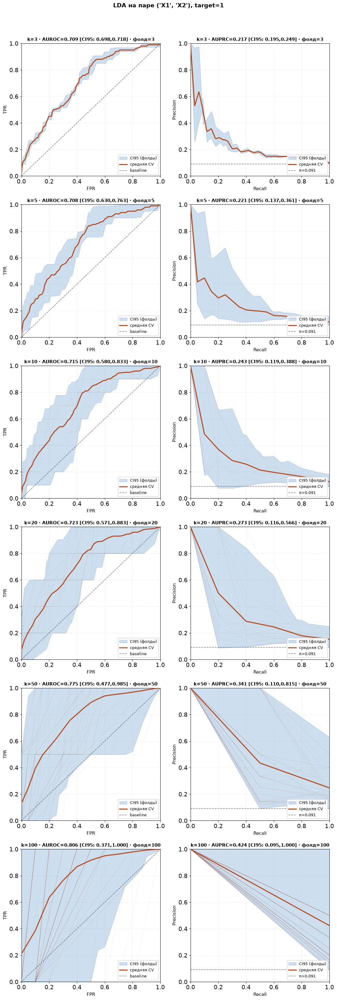

In [76]:
plot_cv_roc(datasets, dataset_key="dfr10",classes=(0, 1), target_class=1, cols=("X1", "X2"))

### [3.7]

Для датасета `dfr1` построить решения LDA на двух, четырех, восьми и шестнадцати признаках. Для каждого решения на одном графике восстановить ROC кривые с доверительными полосами 95%. Аналогично восстановить PR кривые.

In [77]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score


def plot_feature_dim_roc_pr(
    datasets,
    dataset_key="dfr1",
    class_col="class",
    classes=(0, 1),
    features=None,
    dims=(2, 4, 8, 16),
    *,
    feature_selection="corr",     # 'corr' = вложенные префиксы по |corr(признак, y)|; 'first' = первые k колонок
    conf=0.95,
    n_boot=200,
    grid=200,
    seed=123,
    show_fan=False, fan_alpha=0.10, fan_lw=0.6,
    figsize=(13.0, 13.0),         # сетка 2x2
    save_path=None,
    file_dpi=200,
):
    LINE_C = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b"]
    STYLE  = ["-", "--", "-.", ":", (0, (3, 1, 1, 1)), (0, (5, 2))]
    FS_T, FS_A, FS_L = 13, 12, 9

    if features is None:
        features = [c for c in datasets[dataset_key]["data"].columns if c != class_col]

    df = datasets[dataset_key]["data"]
    df = df[df[class_col].isin(list(classes))].reset_index(drop=True)
    y = df[class_col].to_numpy()
    alpha = (1.0 - conf) / 2.0
    xg = np.linspace(0.0, 1.0, grid)
    rng = np.random.default_rng(seed)

    # ---- ранжирование признаков -> вложенные префиксы (не зависит от target: |corr|) ----
    if feature_selection == "corr":
        scored = []
        for f in features:
            v = df[[f, class_col]].dropna()
            r = np.corrcoef(v[f].astype(float), v[class_col].astype(float))[0, 1] if len(v) > 1 else 0.0
            scored.append((f, abs(r) if np.isfinite(r) else 0.0))
        ranked = [f for f, _ in sorted(scored, key=lambda t: t[1], reverse=True)]
    elif feature_selection == "first":
        ranked = list(features)
    else:
        raise ValueError("feature_selection должен быть 'corr' или 'first'")

    subsets = []
    for d in dims:
        cols_d = ranked[:d]
        if len(cols_d) < 2:
            print(f"пропуск dim={d}: недостаточно признаков"); continue
        subsets.append((d, cols_d))

    # ---- хелперы ----
    def _mono(x, yy):
        o = np.lexsort((-yy, x)); xs, ys = x[o], yy[o]
        ux, fi = np.unique(xs, return_index=True)
        return ux, ys[fi]

    def _auc_trapz(fpr, tpr):
        f = np.asarray(fpr, float); t = np.asarray(tpr, float)
        return float(np.sum((f[1:] - f[:-1]) * (t[1:] + t[:-1]) / 2.0))

    def _bootstrap(y, score, kind, target):
        y = np.asarray(y); score = np.asarray(score, float); n = len(y)
        if kind == "roc":
            fpr_c, tpr_c, _ = roc_curve(y, score, pos_label=target)
            metric_c = _auc_trapz(fpr_c, tpr_c)
            x_raw, y_raw = fpr_c, tpr_c
            fx, ty = _mono(fpr_c, tpr_c); yc = np.interp(xg, fx, ty)
        else:
            prec, rec, _ = precision_recall_curve(y, score, pos_label=target)
            rec, prec = rec[::-1], prec[::-1]
            metric_c = average_precision_score(y, score, pos_label=target)
            x_raw, y_raw = rec, prec
            rx, py = _mono(rec, prec); yc = np.interp(xg, rx, py)
        rows, mets = [], []
        for _ in range(n_boot):
            idx = rng.integers(0, n, size=n); yb, sb = y[idx], score[idx]
            if np.unique(yb).size < 2:
                continue
            if kind == "roc":
                fb, tb, _ = roc_curve(yb, sb, pos_label=target)
                fb, tb = _mono(fb, tb); rows.append(np.interp(xg, fb, tb)); mets.append(_auc_trapz(fb, tb))
            else:
                pb, rb, _ = precision_recall_curve(yb, sb, pos_label=target)
                rb, pb = rb[::-1], pb[::-1]; rb, pb = _mono(rb, pb)
                rows.append(np.interp(xg, rb, pb)); mets.append(average_precision_score(yb, sb, pos_label=target))
        mat = np.vstack(rows) if rows else np.empty((0, grid)); mets = np.array(mets)
        lo = np.percentile(mat, 100 * alpha, axis=0) if mat.size else np.full(grid, np.nan)
        hi = np.percentile(mat, 100 * (1 - alpha), axis=0) if mat.size else np.full(grid, np.nan)
        mci = ((float(np.nanpercentile(mets, 100 * alpha)), float(np.nanpercentile(mets, 100 * (1 - alpha))))
               if mets.size else (np.nan, np.nan))
        return dict(xg=xg, yc=yc, lo=lo, hi=hi, mat=mat, x_raw=x_raw, y_raw=y_raw,
                    metric=metric_c, mci=mci)

    # ---- одно обучение LDA на каждое подмножество; скор по столбцу predict_proba ----
    dim_data = []
    for i, (d, cols_d) in enumerate(subsets):
        Xd = df[cols_d].to_numpy(dtype=float)
        mdl = LinearDiscriminantAnalysis().fit(Xd, y)
        proba = mdl.predict_proba(Xd)
        order = list(mdl.classes_)
        dim_data.append((d, cols_d, proba, order, LINE_C[i % len(LINE_C)], STYLE[i % len(STYLE)]))

    # ---- bootstrap ROC/PR для каждого (target, dim) ----
    cache = {}          # target -> (res_list, pi)
    for tgt in classes:
        pi = float((y == tgt).mean())
        res = []
        for d, cols_d, proba, order, color, style in dim_data:
            s = proba[:, order.index(tgt)]
            res.append((d, cols_d, _bootstrap(y, s, "roc", tgt), _bootstrap(y, s, "pr", tgt), color, style))
        cache[tgt] = (res, pi)

    # ---- отрисовка одной ячейки ----
    def _plot(ax, kind, target, res, pi):
        lbl_x, lbl_y = ("FPR", "TPR") if kind == "roc" else ("Recall", "Precision")
        mname = "AUROC" if kind == "roc" else "AUPRC"
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_xlabel(lbl_x, fontsize=FS_A); ax.set_ylabel(lbl_y, fontsize=FS_A)
        ax.grid(alpha=0.2, ls="--")
        if kind == "roc":
            ax.plot([0, 1], [0, 1], ls="--", color="gray", lw=1.2, zorder=1, label="baseline")
        else:
            ax.axhline(pi, ls="--", color="gray", lw=1.2, zorder=1, label=f"baseline π={pi:.3f}")
        for d, cols_d, d_roc, d_pr, color, style in res:
            dd = d_roc if kind == "roc" else d_pr
            if show_fan and dd["mat"].shape[0]:
                step = max(1, dd["mat"].shape[0] // 60)
                for row in dd["mat"][::step]:
                    ax.plot(dd["xg"], row, color=color, alpha=fan_alpha, lw=fan_lw, zorder=2)
            ax.fill_between(dd["xg"], dd["lo"], dd["hi"], color=color, alpha=0.16, zorder=3)
            ax.plot(dd["x_raw"], dd["y_raw"], color=color, lw=2.2, linestyle=style, zorder=5,
                    label=f"{d} призн.: {mname}={dd['metric']:.3f} "
                          f"[CI{conf*100:.0f}: {dd['mci'][0]:.3f},{dd['mci'][1]:.3f}]")
        ax.legend(loc="lower right", fontsize=FS_L, framealpha=0.9)
        ax.set_title(f"Класс {target} · {kind.upper()}", fontsize=FS_T, fontweight="bold")

    # ---- панно 2x2: строки = классы, колонки = ROC | PR ----
    fig, axes = plt.subplots(2, 2, figsize=figsize, squeeze=False)
    for ti, tgt in enumerate(classes):
        res, pi = cache[tgt]
        _plot(axes[ti, 0], "roc", tgt, res, pi)
        _plot(axes[ti, 1], "pr",  tgt, res, pi)

    fig.suptitle(f"{dataset_key} | Классы пары: {list(classes)} | LDA по числу признаков {list(dims)} ",
                 fontsize=FS_T + 1, fontweight="bold", y=0.999)
    plt.tight_layout(rect=(0, 0, 1, 0.98))
    plt.show()

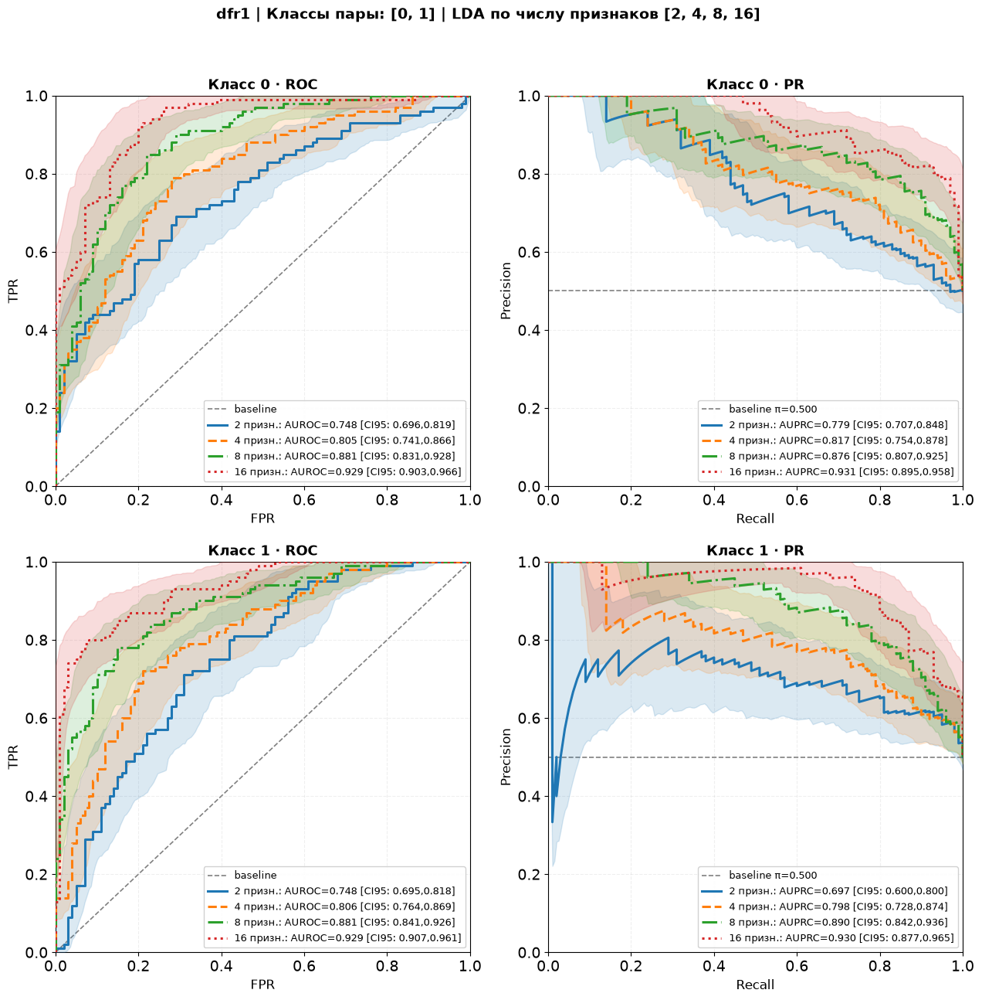

In [78]:
plot_feature_dim_roc_pr(datasets, dataset_key="dfr1", classes=(0, 1))

### [3.8]

Повторить пункт [3.3] для набора алгоритмов LDA, MDC, линейного SVM, LogReg. Повторить пункт [3.4] для алгоритма линейного SVM, сравнив его с LDA, MDC, LogReg.

/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The

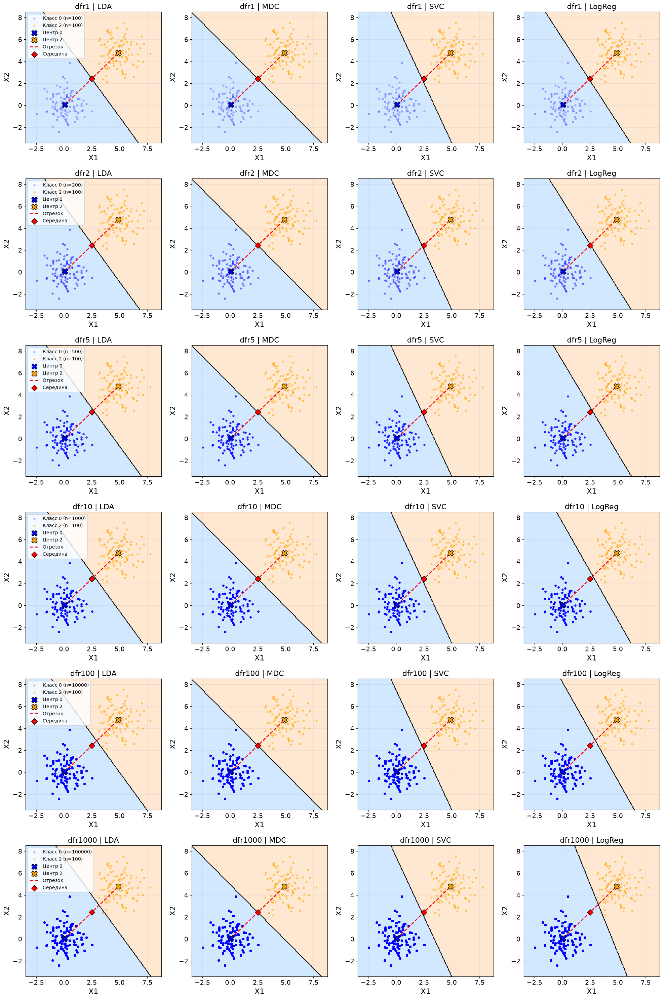

/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The

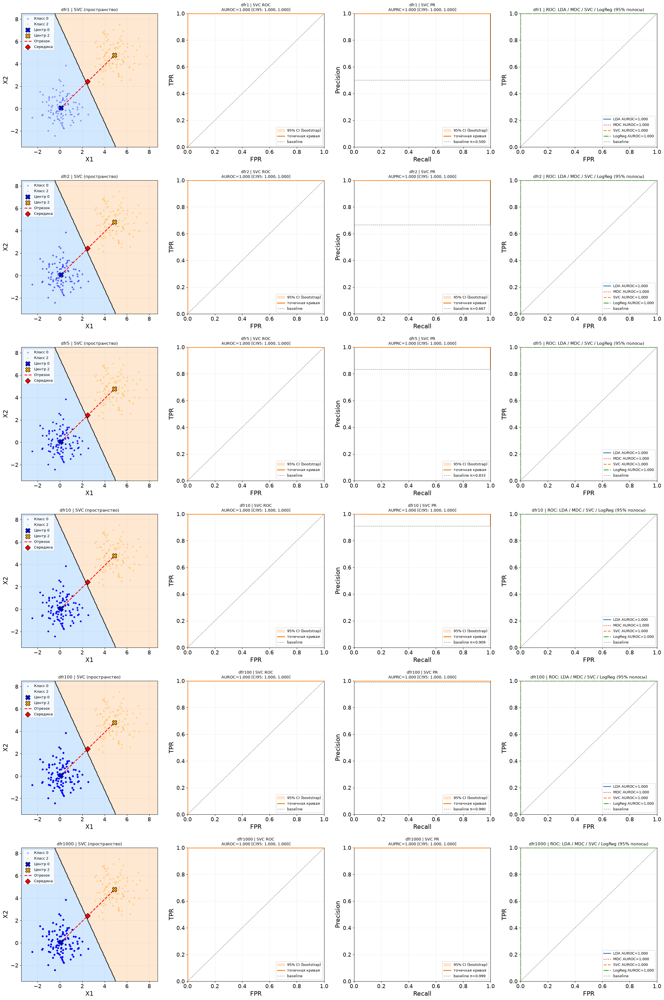

In [79]:
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression

def _models_38A(X, y, centers, seed):    
    return {'LDA': LinearDiscriminantAnalysis(),
            'MDC': MDC(centers),
            'SVC': SVC(kernel='linear', probability=True, random_state=seed),
            'LogReg': LogisticRegression(max_iter=2000, random_state=seed)}

def _models_38B(X, y, centers, seed):     
    return _models_38A(X, y, centers, seed)

C38 = {'LDA':'#1f77b4','MDC':'#d62728','SVC':'#ff7f0e','LogReg':'#2ca02c'}
S38 = {'LDA':'-','MDC':':','SVC':'--','LogReg':'-.'}

plot_diff_methods(target_class_1, classes_1, cols, datasets, model_factory=_models_38A, seed=123)

metrics = run_lda_eval(datasets, features, classes_1, target_class_1, cols, hero='SVC', model_factory=_models_38B, colors=C38, styles=S38)

/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The

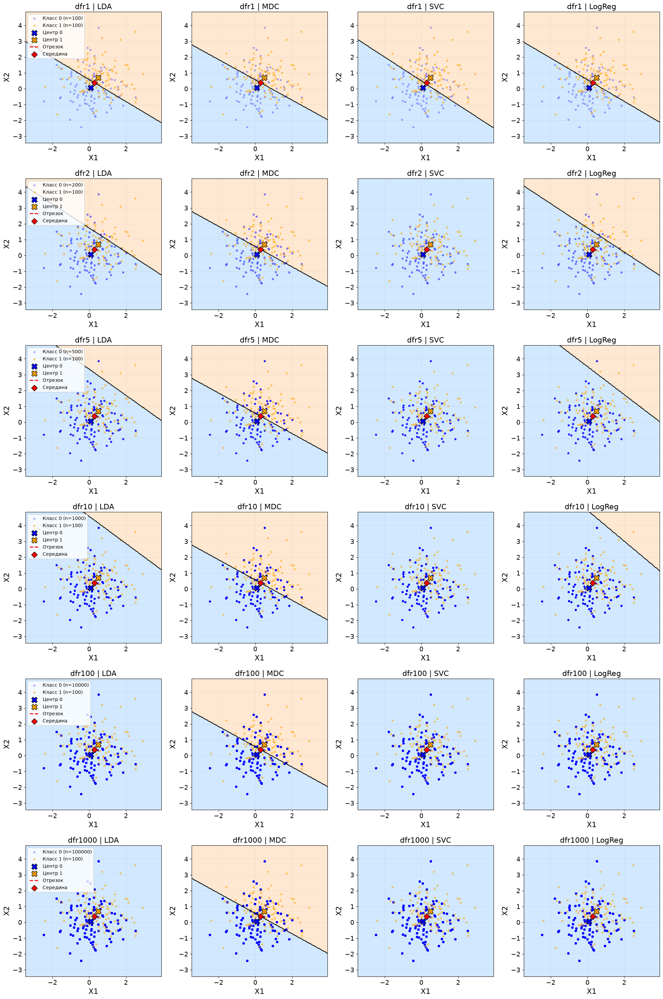

/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
/home/fedosdan2/miniconda3/envs/sdt/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The

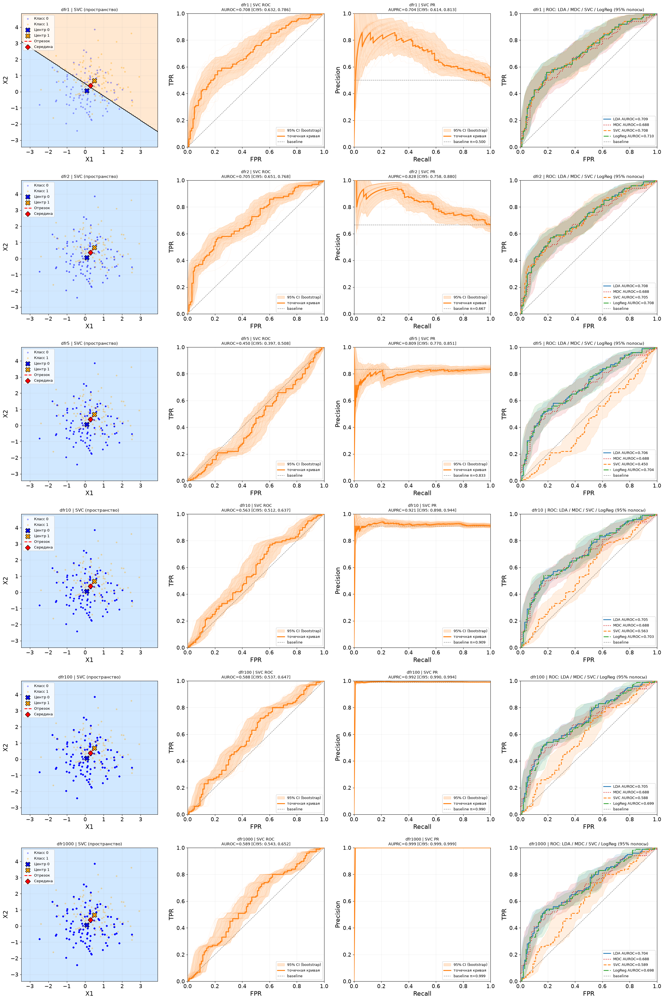

In [80]:
plot_diff_methods(target_class_2, classes_2, cols, datasets, model_factory=_models_38A, seed=123)

metrics = run_lda_eval(datasets, features, classes_2, target_class_2, cols, hero='SVC', model_factory=_models_38B, colors=C38, styles=S38)